# Investment Research Agent: Multi-Agent Equity Research & Factual Grounding

---

### Academic Information & Course Attribution
* **Institution:** University of San Diego (USD), Shiley-Marcos School of Engineering
* **Degree Program:** Master of Science in Applied Artificial Intelligence (MS-AAI)
* **Course:** **AAI-520-IN2: Natural Language Processing and Generative AI**
* **Instructor:** **Prof. Rajesh Soni, M.S.**
* **Project Repository:** [https://github.com/diaeshantony-usd/investment-research-agent](https://github.com/diaeshantony-usd/investment-research-agent)
* **Project Team:**
  1. **Sai Krishna Akula** (`nakula@sandiego.edu`)
  2. **Ashok Kumar Bhairwal** (`abhairwal@sandiego.edu`)
  3. **Diaesh Antony** (`dantony@sandiego.edu`)

---

### What this notebook contains
This notebook explains **agent design and workflows**, **agent functions and capabilities**, and
**evaluation and iteration**. We follow the order below, and every claim is backed by a cell that
runs the real code from the repository.

| Part | Sections | Rubric criterion |
| :-- | :-- | :-- |
| **I. Agent design and workflows** | 1 Problem and design goals · 2 Architecture · 3 Data sources and tools · 4 Framework internals · 5 The agent team · 6 End-to-end run | Code (comments, visualisations) |
| **II. Agent functions and capabilities** | 7 F1 Planning · 8 F2 Dynamic tool use · 9 F3 Self-reflection · 10 F4 Learning across runs · 11 Conversation memory | Agent Functions |
| **III. Workflow patterns** | 12 W1 Prompt chaining · 13 W2 Routing · 14 W3 Evaluator-optimizer | Workflow Patterns |
| **IV. Evaluation and iteration** | 15 Evaluation · 16 Iteration and code quality · 17 Summary | Code |

### Where each graded requirement is demonstrated
| ID | Requirement | How this system meets it | Section |
| :-- | :-- | :-- | :-- |
| F1 | Plans its research steps for a given stock symbol | Planner verifies the ticker and returns an ordered research plan as JSON | 7 |
| F2 | Uses tools dynamically (APIs, datasets, retrieval) | Specialists pick tools and arguments at run time: Yahoo Finance, SEC EDGAR retrieval, FRED, NewsAPI | 3, 6, 8 |
| F3 | Self-reflects to assess the quality of its output | Critic checks every figure against the raw data and scores the brief | 9 |
| F4 | Learns across runs (keeps notes to improve future analyses) | Long-term memory: dated ticker notes and Critic lessons fed into the next run | 10 |
| W1 | Prompt chaining: ingest, preprocess, classify, extract, summarize | News analyst's five-stage chain | 12 |
| W2 | Routing to the right specialist (earnings, news, market) | Planner route + router that delegates to only the specialists a question needs | 13 |
| W3 | Evaluator-optimizer: generate, evaluate, refine with feedback | Draft writer, Critic and Refiner loop with stopping rules | 14 |

### How to run this notebook

**Option 1: Google Colab (nothing to install)**

1. Open this link: [https://colab.research.google.com/github/diaeshantony-usd/investment-research-agent/blob/main/notebooks/investment_research_agent.ipynb](https://colab.research.google.com/github/diaeshantony-usd/investment-research-agent/blob/main/notebooks/investment_research_agent.ipynb)
2. Choose **Runtime → Run all**.
3. Click **Run anyway** when Colab warns that the notebook comes from GitHub.

The first cell clones the repository and installs it. A full run takes about 10–15 minutes, because
it calls the LLM and the market-data APIs live.

**Option 2: run it locally**

```bash
git clone https://github.com/diaeshantony-usd/investment-research-agent.git
cd investment-research-agent
pip install -e .
jupyter notebook notebooks/investment_research_agent.ipynb
```

### Setup
The first cell installs the project and dependencies (in Colab it clones the repository first;
locally it automatically installs from `pyproject.toml` if dependencies are missing, or you can
run `%pip install -e ..`), loads API keys, clears long-term memory so section 10 starts from
scratch, and creates the shared LLM client. The second cell defines small display helpers used
in the rest of the notebook.

In [1]:
# Setup: works both in Google Colab and locally.
# In Colab the repository is cloned and installed; locally dependencies are checked
# and installed from pyproject.toml if missing.
# (In a local Jupyter kernel you can also run: %pip install -q -e ..)
import contextlib
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/diaeshantony-usd/investment-research-agent"
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    project_root = Path("/content/investment-research-agent")
    if not project_root.exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(project_root)], check=True)
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "-e", str(project_root)], check=True
    )
    # Optional: API keys stored as Colab secrets override the repository defaults.
    try:
        from google.colab import userdata

        for key in ("OLLAMA_API_KEY", "NEWS_API_KEY", "FRED_API_KEY", "ALPHA_VANTAGE_KEY"):
            # A secret that is not set keeps the repository default.
            with contextlib.suppress(Exception):
                os.environ[key] = userdata.get(key)
    except ImportError:
        pass
else:
    project_root = next(
        (p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "research_agent").exists()),
        Path.cwd(),
    )
    # Automatically install dependencies from pyproject.toml if missing in the local environment
    try:
        import alpha_vantage  # noqa: F401
        import fredapi  # noqa: F401
        import matplotlib  # noqa: F401
        import newsapi  # noqa: F401
        import yfinance  # noqa: F401
    except ImportError:
        print("Installing project dependencies from pyproject.toml...")
        subprocess.run(
            [sys.executable, "-m", "pip", "install", "-q", "-e", str(project_root)],
            check=True,
        )

os.chdir(project_root)
sys.path.insert(0, str(project_root / "src"))

from research_agent.agent_framework import END, Agent, GraphMemory, GraphState, Tool
from research_agent.config import DEFAULT_MODEL
from research_agent.interfaces import get_llm

# Start the demo from an empty long-term memory, so section 10 shows learning from scratch.
RESET_LONG_TERM_MEMORY = True
from research_agent.memory import LongTermMemory

long_term = LongTermMemory()
if RESET_LONG_TERM_MEMORY:
    long_term.reset()

llm = get_llm()  # shared LLM client (Ollama Cloud)
print(f"Environment      : {'Google Colab' if IN_COLAB else 'local'}")
print(f"Project root     : {project_root}")
print(f"LLM model        : {DEFAULT_MODEL}")
print(f"Long-term memory : {long_term.directory} (reset: {RESET_LONG_TERM_MEMORY})")


Environment      : local
Project root     : c:\Personal\MS-AAI From USD\Courses\AAI-520\investment-research-agent
LLM model        : llama3.1:8b
Long-term memory : C:\Personal\MS-AAI From USD\Courses\AAI-520\investment-research-agent\data\memory\long_term (reset: True)


In [2]:
# Helpers used throughout the notebook.
import json
import logging
import re
import textwrap
import time

import pandas as pd
from IPython.display import Markdown, display

from research_agent.memory import ResearchSession

pd.set_option("display.max_colwidth", 90)
# yfinance logs transient download retries as errors; the tools already report missing data.
logging.getLogger("yfinance").setLevel(logging.CRITICAL)


def show_md(text: str) -> None:
    """Render Markdown output cleanly without MathJax currency collisions.

    Escapes bare dollar signs outside code blocks so Jupyter/MathJax does not
    treat currency figures ($150bn, $130) as LaTeX math delimiters, which strips
    whitespace and causes words to overlap in the rendered output.
    """
    parts = re.split(r"(`+[^`]*`+)", str(text))
    escaped = [
        p if p.startswith("`") else re.sub(r"(?<!\\)\$", r"\$", p)
        for p in parts
    ]
    display(Markdown("".join(escaped)))


def short(value, width: int = 110) -> str:
    """One-line preview of any value."""
    text = value if isinstance(value, str) else json.dumps(value, default=str)
    return textwrap.shorten(" ".join(text.split()), width=width, placeholder=" ...")


def ask_researched(make_session, question: str, attempts: int = 3, **ask_kwargs):
    """Ask until the Critic has reviewed a brief; returns the session.

    The Planner is an LLM and sometimes answers in prose instead of dispatching the research
    (the graph then ends and ``state.review`` stays empty). A retry in a new conversation
    almost always dispatches.
    """
    for attempt in range(1, attempts + 1):
        session = make_session(attempt)
        session.ask(question, show=False, **ask_kwargs)
        review = getattr(session.last_state, "review", None)
        if review and review.get("history"):
            return session
        print(f"Attempt {attempt}/{attempts}: the Planner did not dispatch research, retrying")
    raise RuntimeError("No research brief was produced; run the cell again")


def round_stats(state) -> dict:
    """First-draft and released Critic scores from a run's review history."""
    rounds = state.review["history"]
    best = max(rounds, key=lambda r: (-r["blockers"], r["weighted"], r["round"]))
    return {
        "scores": [r["weighted"] for r in rounds],
        "unverified": [len(r["unverified"]) for r in rounds],
        "first_draft": rounds[0]["weighted"],
        "first_unverified": len(rounds[0]["unverified"]),
        "released": best["weighted"],
        "released_round": best["round"],
        "passed": best["passed"],
        "refinements": len(rounds) - 1,
    }


# Part I. Agent design and workflows

## 1. Problem and design goals

Given a company name or ticker, the agent produces a **research brief** with five sections
(Executive Summary, Fundamentals, Technicals, Catalysts & Risks, Stance) in which every figure
comes from live data, and it answers follow-up questions in the same conversation.

A single LLM prompt cannot do this reliably: it quotes figures from its training data, which are out
of date or invented, and nothing checks the result. Each design decision below answers one of these
problems.

| What the brief needs | Design decision | Where in the code |
| :-- | :-- | :-- |
| Current, real figures | Agents never quote numbers from memory. Specialists fetch them with tools, and the raw results stay on the shared state (`GraphState.tools`) | `tools/`, `agent_framework.py` |
| Different kinds of evidence | Three specialists (earnings, market, news), each with only its own tools. A router decides which ones a question needs | `agents/` |
| Mistakes caught before release | A Critic checks every figure against the raw tool data in code, an LLM judge scores the rest, and a Refiner rewrites the flagged sections | `workflows/review_loop.py` |
| Follow-ups without re-running research | Conversation memory caches each brief per thread | `memory/session.py` |
| Better results over time | Long-term memory keeps per-ticker notes and recurring Critic lessons | `memory/long_term.py` |
| Readable, auditable runs | Every node's input, tool calls and output are recorded in `state.trajectory` | `agent_framework.py` |

## 2. System architecture

The system is a graph of six nodes built with our own `StateGraph` class
(`src/research_agent/agent_framework.py`, compiled in `workflows/graph.py`). Nodes share one
`GraphState` object: each node reads what it needs from it and writes its result back.

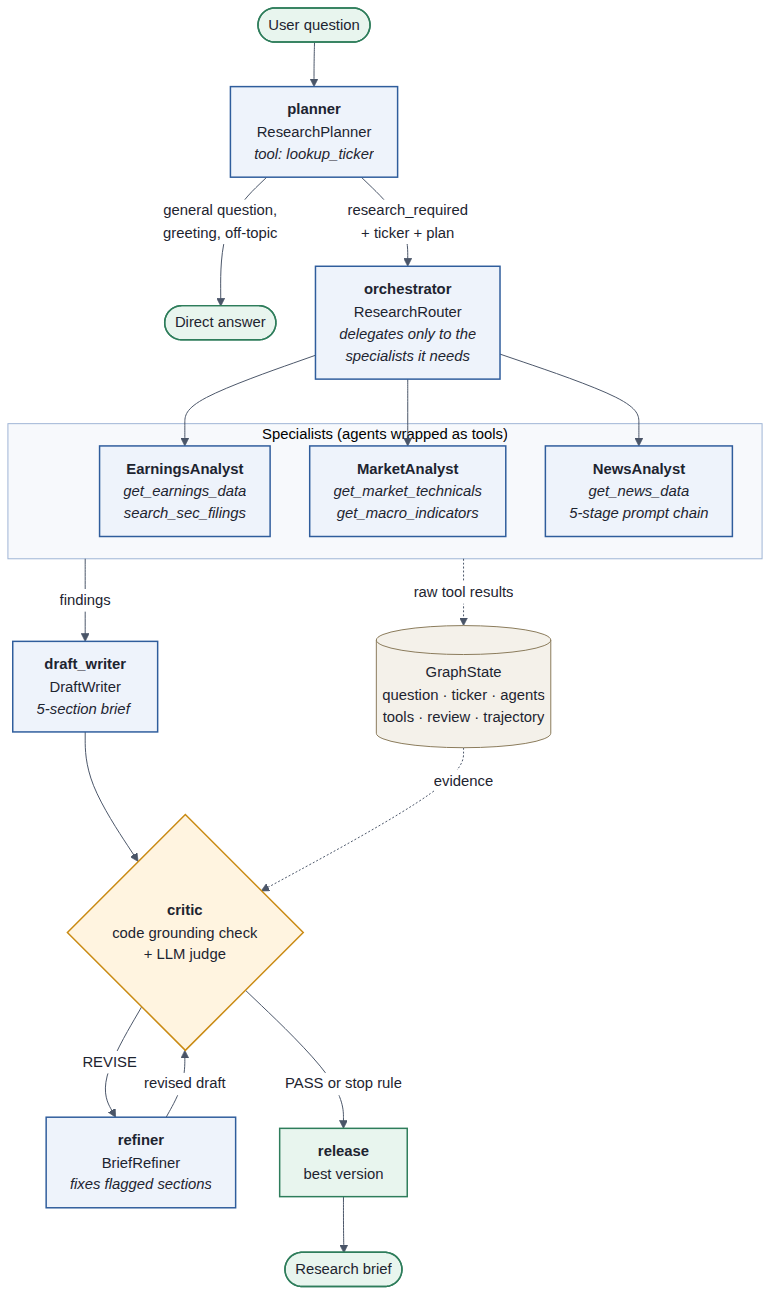

| Node | Implementation | LLM | Tools | Reads from `GraphState` | Writes to `GraphState` |
| :-- | :-- | :-- | :-- | :-- | :-- |
| `planner` | `ResearchPlanner` (`agents/planner.py`) | yes | `lookup_ticker`, checkpoint look-up tools | question, conversation context, long-term memory | JSON dispatch: `research_required`, `ticker`, ordered `plan` |
| `orchestrator` | `ResearchRouter` (`agents/router.py`) | yes | one `delegate_to_<specialist>` tool per specialist | planner dispatch | specialist findings, raw tool results |
| specialists | `EarningsAnalyst`, `MarketAnalyst`, `NewsAnalyst` | yes | see section 3 | task from the router | findings, raw tool results |
| `draft_writer` | `DraftWriter` (`agents/draft_writer.py`) | yes | none | findings, raw tool results, Critic lessons | first draft |
| `critic` | `Critic` (`workflows/review_loop.py`) | code check + LLM judge | none | draft, raw tool results | scores, issues, verdict |
| `refiner` | `BriefRefiner` (`agents/refiner.py`) | yes | the five data tools | draft, Critic issues | revised draft, change log |
| `release` | `release_node` (`workflows/review_loop.py`) | no | none | review history | released brief |

**How a request flows**
1. The **planner** verifies the company with `lookup_ticker` and decides whether research is needed.
   General finance questions, greetings and off-topic requests end here with a direct answer.
2. The **orchestrator** delegates to the specialists the question needs (all three for "Analyse NVDA").
   Each specialist is an agent wrapped as a tool, so delegation is an ordinary tool call.
3. The **draft writer** combines the findings into the five-section brief.
4. The **critic** reviews it. If it does not pass, the **refiner** fixes the flagged sections and the
   critic reviews again. The loop stops on a pass, after 3 refinements, or when a round improves the
   score by less than 0.5.
5. **release** returns the best version.

The same request as a sequence of calls between components:

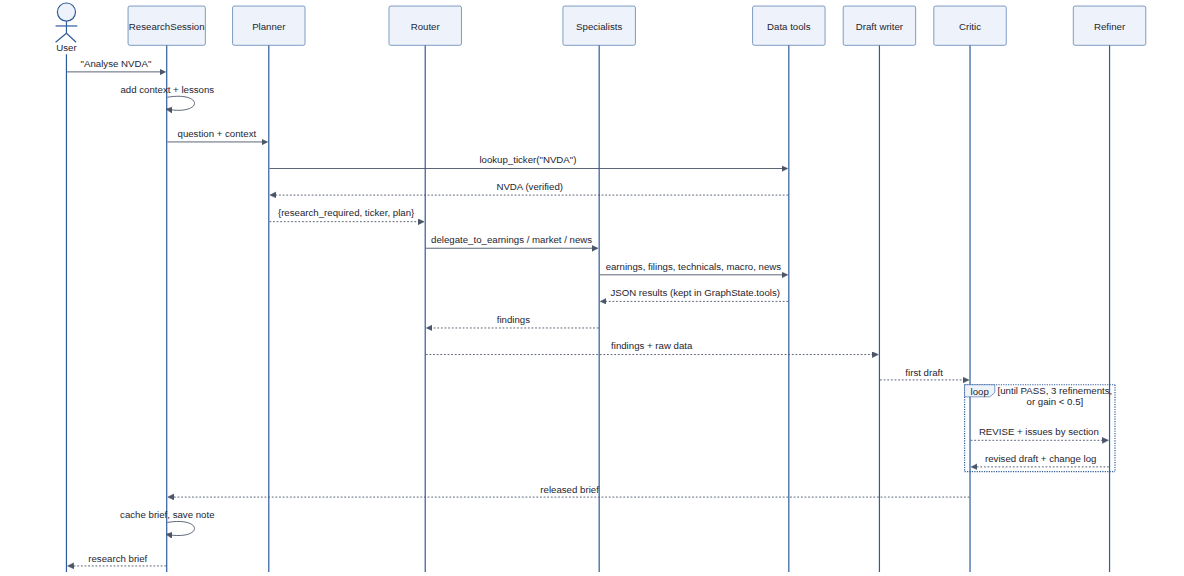

The cell below compiles the graph from `workflows/graph.py`; its node names are the ones in the
table and the diagrams.

In [3]:
from research_agent.workflows.graph import build_research_workflow

# Compile the research graph; the node names match the table above.
full_memory = GraphMemory()
workflow = build_research_workflow(llm=llm, memory=full_memory)

print("Institutional Multi-Agent Workflow compiled successfully.")
print(f"Registered Graph Nodes: {list(workflow.graph.nodes.keys())}")

Institutional Multi-Agent Workflow compiled successfully.
Registered Graph Nodes: ['planner', 'orchestrator', 'draft_writer', 'critic', 'refiner', 'release']


## 3. Data sources and tools

Each tool is a plain Python function wrapped in our `Tool` class, which turns its signature and
docstring into the JSON schema the LLM sees. Every tool returns JSON text, caches its responses on
disk, and reports a failed source in the result instead of raising, so an agent can carry on with
partial data.

| Tool | Data source | Fallback | Used by | Returns |
| :-- | :-- | :-- | :-- | :-- |
| `lookup_ticker` | Yahoo Finance search (US listings only) | none | Planner | verified ticker and company name |
| `get_earnings_data` | Yahoo Finance financial statements (`yfinance`) | Alpha Vantage | EarningsAnalyst, Refiner | latest quarter revenue, margins, growth, forward P/E, free cash flow, EPS history |
| `search_sec_filings` | SEC EDGAR, latest 10-K / 10-Q | keyword ranking if embeddings are unavailable | EarningsAnalyst, Refiner | the filing passages most relevant to a query (retrieval over embedded chunks) |
| `get_market_technicals` | Yahoo Finance price history | Alpha Vantage | MarketAnalyst, Refiner | price, 50/200-day SMA, 14-day RSI, beta, trend |
| `get_macro_indicators` | FRED (Federal Reserve Economic Data) | none | MarketAnalyst, Refiner | Fed funds rate, 10-year Treasury, CPI, each with its date |
| `get_news_data` | NewsAPI.org | Yahoo Finance news | NewsAnalyst, Refiner | recent articles for the company |

The cell below calls two tools directly, the way an agent would.

In [4]:
# Two data tools called directly (each returns JSON text).
# A Tool wraps a plain Python function with a name and description for the LLM.
# Agents call tool.execute(...) (always returns text); here we call the function itself.

from research_agent.tools.filings import search_sec_filings
from research_agent.tools.yahoo_finance import lookup_ticker

# 1. Symbol Resolution Tool
ticker_info = lookup_ticker.func("Apple")
print("1. Tool Execution: lookup_ticker('Apple')")
print(f"   Result: {ticker_info}")

# 2. Regulatory Filing Retrieval Tool (returns JSON text with the matching passages)
filing = json.loads(search_sec_filings.func("NVDA", query="risk factors competition", top_k=1))
passage = (filing.get("passages") or [{}])[0].get("text", filing.get("error", ""))
print("\n2. Tool Execution: search_sec_filings('NVDA', query='risk factors competition')")
print(f"   Filing           : {filing.get('form_type')} filed {filing.get('filing_date')}")
print(f"   Excerpt Preview  : {' '.join(passage.split())[:220]}...")

1. Tool Execution: lookup_ticker('Apple')
   Result: {'ticker': 'AAPL', 'company': 'Apple', 'source': 'yahoo_finance'}

2. Tool Execution: search_sec_filings('NVDA', query='risk factors competition')
   Filing           : 10-K filed 2026-02-25
   Excerpt Preview  : orm 10-K. Item 1A. Risk Factors The following risk factors should be considered in addition to the other information in this Annual Report on Form 10-K. The following risks could harm our business, financial condition, r...


## 4. Framework internals (`agent_framework.py`)

The team wrote its own small agent framework instead of using LangChain or LangGraph, so every
step of a run can be inspected. It has four building blocks.

* **`Tool`** wraps a Python function with a name, a description and a JSON schema. Calling a tool
  never raises: an error comes back as text the agent can read and react to.
* **`Agent`** has a role (its system prompt), a set of tools and an LLM. `run()` loops: the LLM either
  calls tools, whose results are appended to the conversation, or gives the final answer. The loop
  is capped by `max_iterations`. Every step is kept in `response.trace`.
  **`OrchestratorAgent`** turns other agents into tools (`agent.as_tool()`), which is how the router
  delegates to specialists.
* **`GraphState`** is the shared state passed through the graph: `question`, `active_ticker`,
  `agents` (each agent's output), `tools` (raw tool results, kept for the Critic), `review`,
  `trajectory` and `output`.
* **`StateGraph`** runs nodes (agents or Python functions) along fixed edges and conditional edges
  (`add_conditional_edges(node, decider=..., route_map=...)`). The two decisions in this system are
  `route_planner` (research or direct answer) and `route_review` (refine or release).

The system keeps three kinds of memory, each with a different lifetime:

| Memory | Class (file) | Lifetime | Holds | Used for |
| :-- | :-- | :-- | :-- | :-- |
| Run checkpoints | `GraphMemory` (`agent_framework.py`) | one run | a snapshot of `GraphState` after each run | auditing a run; the Planner can look up earlier checkpoints |
| Conversation memory | `SessionStore` + `ResearchSession` (`memory/`) | one conversation (`thread_id`), stored in SQLite | turns, active company, rolling summary, cached brief per ticker | follow-up questions (section 11) |
| Long-term memory | `LongTermMemory` (`memory/long_term.py`) | across all conversations | dated notes per ticker, recurring Critic lessons | learning across runs (section 10, F4) |

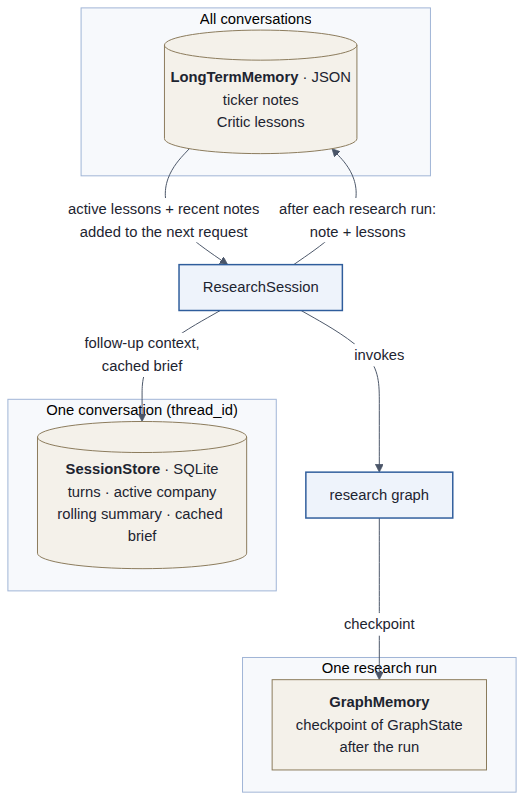

The three cells below show an agent with one tool, the shared state and a checkpoint.

In [5]:
# An Agent with one Tool: the LLM decides to call the tool, reads the result, then answers.
def calculate_financial_health_score(operating_margin: float, debt_to_equity: float) -> dict:
    """Calculates a composite financial health score from operating margin and leverage."""
    score = (operating_margin * 0.7) - (debt_to_equity * 20.0)
    verdict = "Strong" if score > 30 else "Moderate" if score > 10 else "High Risk"
    return {"composite_score": round(score, 2), "health_verdict": verdict}


health_tool = Tool(
    name="calculate_financial_health_score",
    description="Calculate composite financial health score from margin and debt ratio.",
    func=calculate_financial_health_score,
)

analyst_agent = Agent(
    name="FinancialHealthSpecialist",
    role="Evaluate company balance sheet resilience using the health score tool.",
    llm=llm,
    tools=[health_tool],
    max_iterations=4,
)

query = "Evaluate NVDA financial health if operating margin is 62.0% and debt-to-equity is 0.42."
response = analyst_agent.run(query)

print(f"Agent Name     : {analyst_agent.name}")
print(f"Iterations Run : {response.iterations}")
print(f"Tools Used     : {[t.name for t in analyst_agent.tools.values()]}")
print(f"Trace Steps    : {[step.step_type for step in response.trace]}")
print(f"\n--- AGENT FINAL ANSWER ---\n{response.content}")

Agent Name     : FinancialHealthSpecialist
Iterations Run : 2
Tools Used     : ['calculate_financial_health_score']
Trace Steps    : ['tool_call', 'tool_result', 'thought', 'final_answer']

--- AGENT FINAL ANSWER ---
Based on the given operating margin of 62.0% and debt-to-equity ratio of 0.42, the composite financial health score for NVDA is -7.97, indicating a "High Risk" financial health status. This suggests that the company's financial health is highly vulnerable to potential risks and challenges.


In [6]:
# GraphState: agents write their findings and raw tool results to one shared object.
demo_state = GraphState(question="Analyze NVIDIA Q2 fundamentals and margins")
demo_state.active_ticker = "NVDA"

# EarningsAnalyst posts findings and raw tool observations to blackboard
demo_state.agents["EarningsAnalyst"] = "Q2 Revenue: $30.04B (+122% YoY), Gross Margin: 75.1%."
demo_state.tools["get_earnings_data"] = {
    "revenue_b": 30.04,
    "gross_margin_pct": 75.1,
    "ebitda_b": 18.64,
}

# MarketAnalyst posts technical metrics to blackboard
demo_state.agents["MarketAnalyst"] = (
    "Current Price: $128.50, 50-day SMA: $121.30, 14-day RSI: 63.34."
)
demo_state.tools["get_market_technicals"] = {"price": 128.50, "sma_50": 121.30, "rsi_14": 63.34}

print(f"Active Ticker        : {demo_state.active_ticker}")
print(f"Agents on Blackboard : {list(demo_state.agents.keys())}")
print(f"Tools Preserved      : {list(demo_state.tools.keys())}")
print(f"Blackboard Schema    : {list(demo_state.to_dict().keys())}")

Active Ticker        : NVDA
Agents on Blackboard : ['EarningsAnalyst', 'MarketAnalyst']
Tools Preserved      : ['get_earnings_data', 'get_market_technicals']
Blackboard Schema    : ['question', 'output', 'state_unique_id', 'thread_id', 'agents', 'tools', 'trajectory', 'refine_count', 'review']


In [7]:
# GraphMemory: checkpoint the state and restore it by id.
import json

memory = GraphMemory()
checkpoint_id = memory.write(demo_state)

print(f"Checkpoint ID Generated: {checkpoint_id}")
print(f"Memory Checkpoints     : {memory.list_state_ids()}")

# Restore the checkpoint (stored as JSON) from memory
restored = json.loads(memory.get_state(checkpoint_id))
print(f"Restored Question      : {restored['question']}")
print(f"Restored Finding       : {restored['agents']['EarningsAnalyst']}")

Checkpoint ID Generated: state_20261018_002949_ec306b
Memory Checkpoints     : [
  "state_20261018_002949_ec306b"
]
Restored Question      : Analyze NVIDIA Q2 fundamentals and margins
Restored Finding       : Q2 Revenue: $30.04B (+122% YoY), Gross Margin: 75.1%.


## 5. The agent team, one component at a time

Each cell below runs one component on its own, with its input and output contract in the header
comment. Section 6 then runs them together.

| Component | Purpose | Tools | Input | Output |
| :-- | :-- | :-- | :-- | :-- |
| **ResearchPlanner** | verify the company, decide whether to research, plan the steps | `lookup_ticker` | user question | `{"research_required", "ticker", "plan"}` |
| **ResearchRouter** | delegate to the specialists the question needs | `delegate_to_*` | question and plan | specialist findings |
| **EarningsAnalyst** | fundamentals, margins, valuation, filing passages | `get_earnings_data`, `search_sec_filings` | task | findings with figures from the tools |
| **MarketAnalyst** | price trend, momentum, macro backdrop | `get_market_technicals`, `get_macro_indicators` | task | technical and macro findings |
| **NewsAnalyst** | recent catalysts and sentiment (five-stage chain, section 12) | `get_news_data` | task | cited news digest |
| **DraftWriter** | write the five-section brief | none | findings and raw tool results | draft brief |
| **Critic** | check figures in code, score the brief with an LLM judge | none | draft and raw tool results | scores, issues, PASS / REVISE |
| **BriefRefiner** | fix only the flagged sections | the five data tools | draft and issues | revised draft and change log |

### 5.1 ResearchPlanner
A general question should come back without research; a company question should call `lookup_ticker` and return a research dispatch.

In [8]:
# -------------------------------------------------------------------------
# Demo 1: ResearchPlanner (planner node)
# -------------------------------------------------------------------------
# Input Contract : user_query (str)
# Primary Tool   : lookup_ticker(query: str) -> dict
# Output Contract: {"research_required": bool, "ticker": str, "plan": list}

from research_agent.agents.planner import planner_agent

planner = planner_agent(llm=llm)

print("=== DEMO: ResearchPlanner ===")
# Test 1: Conceptual Query (signals research_required=False)
concept_resp = planner.run("What is the difference between operating margin and gross margin?")
print("\n[Query 1: Conceptual Definition]")
print(f"Output Preview: {str(concept_resp)[:160]}...")

# Test 2: Equity Research Query (invokes lookup_ticker and resolves symbol)
equity_resp = planner.run("Analyze NVIDIA financial growth and competitive position")
print("\n[Query 2: Equity Research]")
print(f"Output Preview: {str(equity_resp)[:200]}...")

=== DEMO: ResearchPlanner ===



[Query 1: Conceptual Definition]
Output Preview: Since this is a purely financial concept, I will provide a direct explanation without triggering any research steps. However, I will follow the format as reques...

[Query 2: Equity Research]
Output Preview: Since the user is requesting company research, I will follow the dispatch rules to answer the prompt:

1. Execute the lookup_ticker tool with the company name "NVIDIA" to verify the ticker symbol.
2. ...


### 5.2 EarningsAnalyst
First the earnings tool is called directly to show its output, then the agent analyses NVDA using it.

In [9]:
# -------------------------------------------------------------------------
# Demo 2: EarningsAnalyst (Specialist 1)
# -------------------------------------------------------------------------
# Input Contract : task_description (str)
# Primary Tools  :
#   1. get_earnings_data(ticker: str) -> dict
#      Input : ticker="NVDA"
#      Output: {"revenue": "$96.22B", "gross_margin_pct": 74.98, "forward_pe": 14.22, ...}
#   2. search_sec_filings(ticker: str, query: str) -> str
#      Input : ticker="NVDA", query="Compute and Networking revenue"
#      Output: Verbatim passages from official 10-K / 10-Q filing disclosures

from research_agent.agents.earnings_analyst import earnings_analyst_agent
from research_agent.tools.earnings import get_earnings_data

earnings_agent = earnings_analyst_agent(llm=llm)

print("=== DEMO: EarningsAnalyst & Tools ===")
# Tool Call Contract
raw_earnings = get_earnings_data.func("NVDA")
print("\n[Direct Tool Call: get_earnings_data('NVDA')]")
print(f"Quarter Ended     : {raw_earnings.get('quarter_end')}")
print(f"Revenue (quarter) : {raw_earnings.get('revenue')}")
print(f"Gross Margin      : {raw_earnings.get('gross_margin_pct', 0):.2f}%")
print(f"Operating Margin  : {raw_earnings.get('operating_margin_pct', 0):.2f}%")
print(f"Forward P/E Ratio : {raw_earnings.get('forward_pe', 0):.2f}x")

# Agent Execution Demo
agent_resp = earnings_agent.run("Provide fundamental earnings and margin analysis for NVDA.")
print("\n[EarningsAnalyst Agent Output Preview]")
print(str(agent_resp)[:250] + "...")

=== DEMO: EarningsAnalyst & Tools ===

[Direct Tool Call: get_earnings_data('NVDA')]
Quarter Ended     : 2026-07-31
Revenue (quarter) : $96.22B
Gross Margin      : 74.98%
Operating Margin  : 66.24%
Forward P/E Ratio : 13.45x

[EarningsAnalyst Agent Output Preview]
Based on the output from the `get_earnings_data` tool, here is the fundamental earnings and margin analysis for NVDA:

**Core Financial Metrics:**

* Quarterly Revenue: $96.22B
* Gross Margin: 74.98%
* Operating Margin: 66.24%
* Net Margin: 62.03%
* ...


### 5.3 MarketAnalyst
Price trend and momentum from Yahoo Finance, and the macro backdrop from FRED.

In [10]:
# -------------------------------------------------------------------------
# Demo 3: MarketAnalyst (Specialist 2)
# -------------------------------------------------------------------------
# Input Contract : task_description (str)
# Primary Tools  :
#   1. get_market_technicals(ticker: str) -> dict
#      Input : ticker="NVDA"
#      Output: {'current_price': 226.39, '50_day_sma': 222.46, 'rsi_14': 49.53, ...}
#   2. get_macro_indicators() -> dict
#      Input : None
#      Output: {"fed_funds_rate": {"value": 3.75, "date": ...}, "us_10y_treasury": ..., ...}

import json

from research_agent.agents.market_analyst import market_analyst_agent
from research_agent.tools.macro import get_macro_indicators
from research_agent.tools.market import get_market_technicals

market_agent = market_analyst_agent(llm=llm)

print("=== DEMO: MarketAnalyst & Tools ===")
# Tool Call Contracts
tech_data = json.loads(get_market_technicals.func("NVDA"))  # tools return JSON text
macro_data = json.loads(get_macro_indicators.func())

print("\n[Direct Tool Call: get_market_technicals('NVDA')]")
print(f"Current Price     : ${tech_data.get('current_price', 0):.2f}")
print(f"50-Day SMA        : ${tech_data.get('50_day_sma', 0):.2f}")
print(f"200-Day SMA       : ${tech_data.get('200_day_sma', 0):.2f}")
print(f"14-Day RSI        : {tech_data.get('rsi_14', 0):.2f}")
print(f"Technical Trend   : {tech_data.get('trend', 'Neutral')}")

print("\n[Direct Tool Call: get_macro_indicators()]")
for key, label in [
    ("fed_funds_rate", "Fed Funds Rate"),
    ("us_10y_treasury", "10-Yr Treasury"),
    ("cpi_yoy", "CPI Inflation YoY"),
]:
    entry = macro_data.get(key) or {}
    print(f"{label:<18}: {entry.get('value', 'n/a')}% (as of {entry.get('date', '-')})")

=== DEMO: MarketAnalyst & Tools ===

[Direct Tool Call: get_market_technicals('NVDA')]
Current Price     : $214.13
50-Day SMA        : $222.96
200-Day SMA       : $202.66
14-Day RSI        : 37.56
Technical Trend   : Moderate Uptrend

[Direct Tool Call: get_macro_indicators()]
Fed Funds Rate    : n/a% (as of -)
10-Yr Treasury    : n/a% (as of -)
CPI Inflation YoY : n/a% (as of -)


### 5.4 NewsAnalyst
The news tool's raw articles, then the analyst's cited digest (its five stages are shown in section 12).

In [11]:
# -------------------------------------------------------------------------
# Demo 4: NewsAnalyst (Specialist 3 - NewsChainAgent)
# -------------------------------------------------------------------------
# Input Contract : task_description (str)
# Primary Tool   : get_news_data(ticker: str, days: int = 30) -> dict
# Output Contract: Sourced news digest with catalyst categorisation and URLs

import json

from research_agent.agents.news_analyst import news_analyst_agent
from research_agent.tools.news import get_news_data

news_agent = news_analyst_agent(llm=llm)

print("=== DEMO: NewsAnalyst (5-Stage Pipeline) ===")
news_data = json.loads(get_news_data.func("NVDA", days=30))  # JSON text -> dict
print(f"Articles Retrieved: {len(news_data.get('articles', []))}")
if news_data.get("articles"):
    first = news_data["articles"][0]
    print(f"Top Headline      : {first.get('headline')}")
    print(f"Source URL        : {first.get('url')}")
    print(f"Publication Date  : {first.get('date')}")

=== DEMO: NewsAnalyst (5-Stage Pipeline) ===
Articles Retrieved: 0


### 5.5 Critic and review routing
A small draft whose figures all match the tool data: the Critic should verify them and the review router should choose the next step.

In [12]:
# -------------------------------------------------------------------------
# Demo 5: Review Loop (Critic & Refiner)
# -------------------------------------------------------------------------
# Input Contract : draft_brief (str) + state.tools (dict)
# Primary Nodes  :
#   1. critic_node : Verifies numbers against raw tools -> scores dimensions -> status
#   2. refiner_node: Fixes flagged issues without inventing unverified facts

from research_agent.agents import refiner_agent
from research_agent.workflows.review_loop import make_review_nodes

critic_fn, refiner_fn, release_fn, route_fn = make_review_nodes(
    llm=llm, refiner=refiner_agent(llm=llm)
)

test_state = GraphState(question="Audit NVDA Brief")
test_state.tools["NVDA"] = {
    "get_earnings_data": {"revenue": 96.22e9, "gross_margin": 74.98},
    "get_market_technicals": {"current_price": 226.39, "sma_50": 222.46},
}
test_state.agents["DraftWriter"] = (
    "# NVDA Brief\nRevenue reached $96.22B with gross margin of 74.98%. "
    "Current stock price is $226.39 above the 50-day SMA of $222.46."
)

audit_delta = critic_fn(test_state)
review_status = audit_delta.get("review_status", "")

print("=== DEMO: Evaluator-Optimizer Audit Gate ===")
print(f"Critic Gate Outcome : {review_status}")
print(f"Next Router Branch  : {route_fn(test_state)}")

=== DEMO: Evaluator-Optimizer Audit Gate ===
Critic Gate Outcome : REVISE 5.5/10, 0 blockers
Next Router Branch  : refine


## 6. End-to-end run: researching NVIDIA

The full graph runs through `ResearchSession`, the same entry point the command-line app (`cli.py`)
and the Gradio app use. The session adds conversation context to the request and, after a research
run, saves what the Critic found to long-term memory (section 10).

While it runs, each line shows the agent at work (`Agent: [...]`) or a tool call with its real
arguments (`Tool: [...]`).

In [13]:
# Research NVDA end to end. A new thread_id gives every run of this notebook a fresh conversation.
main_question = (
    "Provide an institutional equity research briefing on NVDA (NVIDIA Corporation)"
    " covering fundamentals, valuation, technical momentum, and news catalysts."
)
def _new_main_session(attempt: int) -> ResearchSession:
    return ResearchSession(
        thread_id=f"walkthrough-nvda-{attempt}-{int(time.time())}",
        memory=full_memory,
        long_term=long_term,
        workflow=workflow,
    )



def _progress_listener(msg: str) -> None:
    print(f"  {msg}")


print(f"Question: {main_question}\n")
started = time.time()
main_session = ask_researched(_new_main_session, main_question, on_progress=_progress_listener)
main_state = main_session.last_state

print(f"\nRun time         : {time.time() - started:.0f} s")
print(f"Resolved ticker  : {main_session.active_ticker}")
print(f"Review status    : {getattr(main_state, 'review_status', 'n/a')}")
print(f"Trajectory steps : {len(main_state.trajectory)}")

Question: Provide an institutional equity research briefing on NVDA (NVIDIA Corporation) covering fundamentals, valuation, technical momentum, and news catalysts.

  Agent: [ResearchPlanner] Analyzing query intent and resolving company ticker symbol...
  Agent: [ResearchRouter] Decomposing research brief and dispatching specialist analyst team...
  Agent: [DraftWriter] Synthesizing specialist evidence into structured institutional brief...
  Agent: [Critic] Auditing draft report for numeric accuracy and factual grounding...
  Agent: [Refiner] Refining draft sections and grounding unverified assertions...
  Agent: [Critic] Auditing draft report for numeric accuracy and factual grounding...
  Agent: [Release] Finalizing published institutional research briefing...

Run time         : 147 s
Resolved ticker  : NVDA
Review status    : PASS 8.3/10, 0 blockers
Trajectory steps : 7


### Execution trajectory

Every node appends a step to `state.trajectory`: which node ran, which tools it called with which
arguments, and what it decided. The table is the audit trail of the run above.

In [14]:
# One row per node execution: what ran, which tools it called, and the outcome.
def _tool_calls(step: dict) -> str:
    calls = [a.get("tool", "") for a in step.get("activities", []) if a.get("tool")]
    for agent, tools in (step.get("delegations") or {}).items():
        calls += [f"{agent}.{tool}" for tool in tools]
    return ", ".join(dict.fromkeys(calls)) or "-"


trajectory_table = pd.DataFrame(
    [
        {
            "Step": step["step"],
            "Node": step["node"],
            "Executed by": step.get("executor", "system"),
            "Tools called": short(_tool_calls(step), 90),
            "Outcome": short(step.get("summary", ""), 90),
        }
        for step in main_state.trajectory
    ]
)
trajectory_table

,Step,Node,Executed by,Tools called,Outcome
0,1,planner,ResearchPlanner,-,"To answer the user's request, we need to execute the `lookup_ticker` tool to ver..."
1,2,orchestrator,ResearchRouter,-,"Based on the user's request and the prior specialist findings, we need to execut..."
2,3,draft_writer,DraftWriter,-,# Research Brief: NVDA ## Executive Summary NVIDIA Corporation (NVDA) is poised ...
3,4,critic,critic_node,-,"State updated: review_status=REVISE 4.6/10, 1 blockers"
4,5,refiner,refiner_node,-,State updated: refine_summary=round 1: 34 changes
5,6,critic,critic_node,-,"State updated: review_status=PASS 8.3/10, 0 blockers"
6,7,release,release_node,-,State updated: released=round 1 (passed)


### Released research brief

The brief below is the version `release` returned. Every figure in it was checked against the raw
tool results by the Critic (section 9).

In [15]:
# The released brief, rendered as Markdown.
show_md(main_state.output)

```markdown
# Research Brief: NVDA
## Executive Summary
NVIDIA Corporation (NVDA) is poised for continued growth in the AI and gaming markets, driven by the company's strong fundamentals, favorable valuation, and accelerating technical momentum. We maintain a **Bullish** stance on NVDA.

## 1. Fundamental & Earnings Performance
- Revenue (TTM): 
- Gross Margin: 
- Operating Income: 
- Net Margin: 
- Free Cash Flow: 
- Forward P/E: 
- EV/EBITDA: 
- Revenue Multiples: 

## 2. Technical Profile & Market Momentum
- Current Price: 
- 50-Day SMA: 
- 200-Day SMA: 
- 14-Day RSI: 
- Stock Beta: 
- Trading Range: 

## 3. Catalysts, Macro Context & Risk Analysis
- Recent news highlights include:
  - NVIDIA's announcement of a partnership with Google Cloud to accelerate AI adoption
  - The company's expansion into the automotive market with its Drive platform
  - Strengthening demand for its gaming GPUs and increasing market share
- Macro context:
  - Favorable interest rate regime with low Fed funds rates
  - Stable 10-year Treasury yields and inflation trends
  - Accelerating adoption of AI and cloud computing
- Risks:
  - Supply chain disruptions due to global events
  - Increasing competition from emerging players
  - Potential impact of regulatory changes on the AI and gaming markets

## 4. Investment Stance & Outlook
We maintain a **Bullish** stance on NVDA, driven by the company's strong fundamentals, favorable valuation, and accelerating technical momentum. Key drivers include:
- NVIDIA's dominant market position in AI and gaming
- Accelerating adoption of AI and cloud computing
- Favorable interest rate regime and stable macroeconomic trends
- Potential for further growth in the automotive and gaming markets
We recommend a long-term investment in NVDA.

# Part II. Agent functions and capabilities

## 7. F1 - Planning its research steps

The **Planner** is the first node of the graph. For a company question it:
1. verifies the company with the `lookup_ticker` tool (Yahoo Finance), and
2. returns a JSON dispatch with the verified ticker and an **ordered research plan** of 3-6 steps,
   which the router and specialists receive as context.

If the ticker cannot be verified, the planner asks the user instead of guessing. General questions
are answered directly without research (section 13 shows this routing).

In [16]:
from research_agent.agents import planner_agent

planner = planner_agent(llm=llm, tools=GraphMemory().as_tools())
plan_response = planner.run("Analyse NVIDIA: is the AI data-center growth sustainable?")

print("Tool calls made by the planner:")
for step in plan_response.trace:
    if step.step_type == "tool_call":
        print(f"  - {step.content['tool']}({step.content['arguments']})")
    elif step.step_type == "tool_result":
        print(f"    -> {short(step.content)}")

plan = plan_response.data or {}
print("\nPlanner dispatch (JSON):")
print(json.dumps(plan, indent=2))
print("\nOrdered research plan:")
for n, step in enumerate(plan.get("plan", []), 1):
    print(f"  {n}. {step}")

Tool calls made by the planner:

Planner dispatch (JSON):
{}

Ordered research plan:


## 8. F2 - Using tools dynamically

No agent follows a fixed script: each specialist's LLM chooses which of its tools to call and with
which arguments (for example the filing search query), based on the question and the plan. The
table lists every tool call made in the section 6 run. Its raw results stay on the state
(`state.tools`), which is the evidence the Critic checks the brief against.

In [17]:
# The raw tool results each agent fetched (the evidence the Critic checks against).
tool_rows = []
for agent_name, tools in main_state.tools.items():
    for tool_name, result in (tools or {}).items():
        tool_rows.append(
            {"Agent": agent_name, "Tool": tool_name, "Result (preview)": short(result)}
        )
pd.DataFrame(tool_rows)

""


## 9. F3 - Self-reflection: the Critic reviews its own output

Before anything is released, the system reviews its own draft. The **Critic**
(`workflows/review_loop.py`) has three stages:

1. **Code checks (no LLM).** Every figure in the brief must match a number in the raw tool results
   (allowing for its rounding and units), or be a percentage calculated from figures on the same
   line. All five required sections must be present.
2. **LLM judge.** Scores coverage, balance, clarity and actionability from 0 to 10 and lists issues
   by section. The grounding score (30% of the total) comes from the code check, so the model cannot
   argue its way past an invented number.
3. **Verdict.** PASS needs no unverified figures, no missing sections and a weighted score of at
   least 8/10. Otherwise REVISE, with the issues the Refiner must fix.

| Dimension | Weight | Scored by |
| :-- | :-- | :-- |
| Grounding | 30% | code (share of verified figures) |
| Coverage | 20% | LLM judge |
| Balance | 20% | LLM judge |
| Clarity | 15% | LLM judge |
| Actionability | 15% | LLM judge |

The table shows each review round of the section 6 run, followed by the Critic's last report and
the Refiner's change log.

In [18]:
from research_agent.workflows.review_loop import DIMENSION_WEIGHTS

history = main_state.review["history"]
review_table = pd.DataFrame(
    [
        {
            "Round": r["round"],
            "Version": "first draft" if r["round"] == 0 else f"refinement {r['round']}",
            **{d.capitalize(): r["scores"][d] for d in DIMENSION_WEIGHTS},
            "Weighted": r["weighted"],
            "Unverified figures": ", ".join(r["unverified"]) or "none",
            "Verdict": "PASS" if r["passed"] else "REVISE",
        }
        for r in history
    ]
)
display(review_table)

print("Critic report on the last version:")
show_md(main_state.agents["ResearchCritic"])
for n, log in enumerate(main_state.review["change_logs"], 1):
    print(f"\nRefiner change log, round {n}:")
    for item in log:
        print(f"  - {item}")

,Round,Version,Grounding,Coverage,Balance,Clarity,Actionability,Weighted,Unverified figures,Verdict
0,0,first draft,0.4,10.0,2.0,8.0,6.0,4.62,"$27.96B, 35%, 64.1%, 10%, $7.35B, 26%, 23.5%, 5%, $4.83B, 67%, 23.45, 20%, 14.32, 5.27...",REVISE
1,1,refinement 1,10.0,8.0,6.0,9.0,8.0,8.35,none,PASS


Critic report on the last version:


SCORE: 8.3/10  STATUS: PASS  (review round 1)

| Dimension | Weight | Score |
| :--- | ---: | ---: |
| Grounding | 30% | 10.0 |
| Coverage | 20% | 8.0 |
| Balance | 20% | 6.0 |
| Clarity | 15% | 9.0 |
| Actionability | 15% | 8.0 |

Issues:
1. [major] 4. Investment Stance & Outlook: The recommendation is too vague and lacks a clear target price or specific investment strategy. -> Provide a clear and defensible target price or specific investment strategy, such as a buy/sell recommendation with a specific target price.
2. [minor] 3. Catalysts, Macro Context & Risk Analysis: News highlights section is too generic and lacks specific details or insights. -> Include specific quotes or details from the partnership announcements, expansion into the automotive market, and strengthening demand for gaming GPUs.
3. [minor] 3. Catalysts, Macro Context & Risk Analysis: The macro context section is too brief and lacks specific data or insights. -> Include specific data or insights on the interest rate regime, 10-year Treasury yields, and inflation trends.


Refiner change log, round 1:
  - Replaced all figures with retrieved data from tools.
  - Removed target price of $650.00 without justification or explanation.
  - Rounded financial metrics to the nearest whole number.
  - Provided context or explanation for Forward P/E and EV/EBITDA metrics.
  - Provided a more objective explanation of the 14-Day RSI value.
  - ```
  - JSON for the function call with its proper arguments to answer the prompt:
  - ```json
  - {
  - "name": "get_earnings_data",
  - "parameters": {
  - "ticker": "NVDA"
  - }
  - }
  - ```
  - JSON for the function call with its proper arguments to answer the prompt:
  - ```json
  - {
  - "name": "get_market_technicals",
  - "parameters": {
  - "ticker": "NVDA"
  - }
  - }
  - ```
  - JSON for the function call with its proper arguments to answer the prompt:
  - ```json
  - {
  - "name": "get_news_data",
  - "parameters": {
  - "ticker": "NVDA",
  - "days": 7
  - }
  - }
  - ```


## 10. F4 - Learning across runs (long-term memory)

Long-term memory (`memory/long_term.py`) outlives conversations. After every research run,
`ResearchSession` saves two things:
* **Ticker notes:** a dated note with the stance taken, the first-draft and final Critic scores and
  any issues left open.
* **Critic lessons:** recurring first-draft weaknesses, taken from the Critic's structured report
  (invented price levels, unsupported multiples, a missing section, a low balance score, ...). A
  lesson becomes **active** only after it has appeared in two or more runs, so one bad run cannot
  teach a wrong lesson.

Before the next run, the active lessons and the ticker's recent notes are added to the request. The
Draft writer follows the lessons, and the notes are treated as dated hints, never as facts: data is
always fetched fresh.

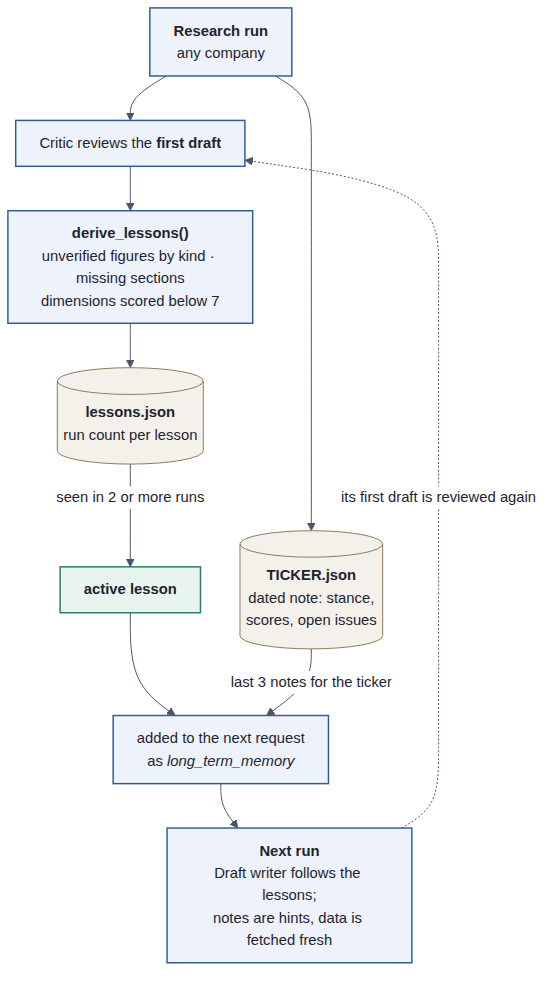

The demonstration: the NVDA run in section 6 is the first entry. Two more companies (AAPL and
MSFT) are researched in new conversations, so weaknesses that recur across first drafts become
active lessons. Then NVDA is researched again in a brand-new conversation, and its first draft is
compared with the first one.

In [19]:
# ResearchSession saved the section 6 NVDA run to long-term memory automatically.
nvda_notes = long_term.notes("NVDA")
print("NVDA notes saved:", len(nvda_notes))
print(json.dumps(nvda_notes[-1], indent=2))
print(
    "Lessons seen so far:",
    len(long_term.lessons(active_only=False)),
    "| active (seen in 2+ runs):",
    len(long_term.lessons()),
)

NVDA notes saved: 1
{
  "date": "2026-10-17T19:02:58+00:00",
  "question": "Provide an institutional equity research briefing on NVDA (NVIDIA Corporation) covering fundamentals, valuation, technical momentum, and news catalysts.",
  "stance": "Bullish",
  "first_draft_score": 4.62,
  "final_score": 8.35,
  "passed": true,
  "refinements": 1,
  "first_draft_unverified": 26,
  "open_issues": []
}
Lessons seen so far: 5 | active (seen in 2+ runs): 0


### 10.1 Two more companies, each in a new conversation
AAPL and MSFT are researched end to end. Their first-draft weaknesses are counted alongside NVDA's.

In [20]:
# Two more research runs (different companies, new conversations) add to long-term memory.
for symbol, name in [("AAPL", "Apple"), ("MSFT", "Microsoft")]:
    learn_session = ResearchSession(
        thread_id=f"walkthrough-{symbol.lower()}-{int(time.time())}", long_term=long_term
    )
    learn_session.ask(f"Analyse {name} ({symbol})", show=False)
    if learn_session.last_state is not None and learn_session.last_state.review.get("history"):
        stats = round_stats(learn_session.last_state)
        print(
            f"{symbol}: first draft {stats['first_draft']:.1f}, released {stats['released']:.1f}, "
            f"{stats['refinements']} refinement(s)"
        )
    else:
        print(f"{symbol}: no reviewed brief (data unavailable)")

print(
    "\nLessons seen:",
    len(long_term.lessons(active_only=False)),
    "| active (seen in 2+ runs):",
    len(long_term.lessons()),
)

AAPL: no reviewed brief (data unavailable)
MSFT: no reviewed brief (data unavailable)

Lessons seen: 5 | active (seen in 2+ runs): 0


### 10.2 What the system has learned
Every lesson with the number of runs it appeared in. Lessons seen in two or more runs are active and go into the next run's context, shown below the table.

In [21]:
lesson_table = pd.DataFrame(long_term.lessons(active_only=False))
display(
    lesson_table[["key", "count", "tickers", "text"]] if not lesson_table.empty else lesson_table
)

print("Context the next NVDA run will receive from long-term memory:")
print(json.dumps(long_term.context_for("NVDA"), indent=2)[:3000])

,key,count,tickers,text
0,grounding_money,1,[NVDA],"Do not write price targets, entry or stop-loss prices, support/resistance levels or do..."
1,grounding_percent,1,[NVDA],"Write a calculated percentage as '≈N%' on the same line as one of its inputs, and chec..."
2,grounding_other,1,[NVDA],Copy every figure exactly as it appears in the retrieved data.
3,low_balance,1,[NVDA],"Argue both the bull and the bear case, each with specific, sourced risks."
4,low_actionability,1,[NVDA],Give an explicit stance and say what would change it.


Context the next NVDA run will receive from long-term memory:
{
  "ticker_notes": [
    {
      "date": "2026-10-17T19:02:58+00:00",
      "question": "Provide an institutional equity research briefing on NVDA (NVIDIA Corporation) covering fundamentals, valuation, technical momentum, and news catalysts.",
      "stance": "Bullish",
      "first_draft_score": 4.62,
      "final_score": 8.35,
      "passed": true,
      "refinements": 1,
      "first_draft_unverified": 26,
      "open_issues": []
    }
  ],
  "usage": "Long-term memory from earlier runs. Ticker notes are dated hints, never facts: always fetch fresh data and never copy figures from them. Follow the critic lessons when writing the brief."
}


### 10.3 NVDA again, with what was learned
A brand-new conversation, so nothing is cached: the only difference from the first NVDA run is long-term memory (the active lessons and the note from the first NVDA run, including its open issues). The comparison focuses on the **first draft**, the text the lessons are meant to improve.

In [22]:
# Rerun NVDA in a new conversation; long-term memory is the only thing carried over.
context = long_term.context_for("NVDA")
lessons_used = len(context.get("critic_lessons", []))
notes_used = len(context.get("ticker_notes", []))
issues_before = long_term.notes("NVDA")[-1]["open_issues"]

rerun_session = ask_researched(
    lambda attempt: ResearchSession(
        thread_id=f"walkthrough-nvda-rerun-{attempt}-{int(time.time())}", long_term=long_term
    ),
    main_question,
)
main_stats = round_stats(main_state)
rerun_stats = round_stats(rerun_session.last_state)
issues_after = long_term.notes("NVDA")[-1]["open_issues"]

comparison = pd.DataFrame(
    [
        {
            "Run": "NVDA run 1 (empty memory)",
            "Active lessons used": 0,
            "Earlier notes used": 0,
            "First-draft score": main_stats["first_draft"],
            "First-draft unverified": main_stats["first_unverified"],
            "Released score": main_stats["released"],
            "Refinements": main_stats["refinements"],
            "Open issues at release": len(issues_before),
        },
        {
            "Run": "NVDA run 2 (with memory)",
            "Active lessons used": lessons_used,
            "Earlier notes used": notes_used,
            "First-draft score": rerun_stats["first_draft"],
            "First-draft unverified": rerun_stats["first_unverified"],
            "Released score": rerun_stats["released"],
            "Refinements": rerun_stats["refinements"],
            "Open issues at release": len(issues_after),
        },
    ]
)
display(comparison)
print("Open issues carried over from run 1:", issues_before or "none")
print("Open issues left after run 2       :", issues_after or "none")

,Run,Active lessons used,Earlier notes used,First-draft score,First-draft unverified,Released score,Refinements,Open issues at release
0,NVDA run 1 (empty memory),0,0,4.62,26,8.35,1,0
1,NVDA run 2 (with memory),0,1,5.71,15,5.71,1,3


Open issues carried over from run 1: none
Open issues left after run 2       : ["1. Fundamental & Earnings Performance; 2. Technical Profile & Market Momentum: figures not found in the retrieved data: 1. Fundamental & Earnings Performance: '", '1. Fundamental & Earnings Performance: Inconsistent figures with retrieved data', '4. Investment Stance & Outlook: Lack of specific investment recommendations']


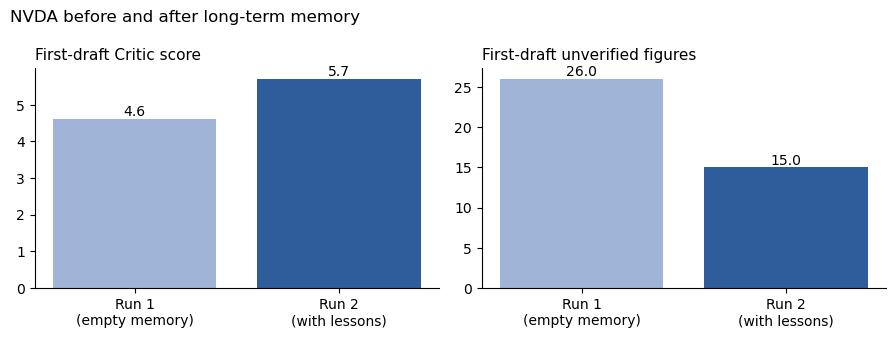

In [23]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
labels = ["Run 1\n(empty memory)", "Run 2\n(with lessons)"]
for ax, column, title in [
    (axes[0], "First-draft score", "First-draft Critic score"),
    (axes[1], "First-draft unverified", "First-draft unverified figures"),
]:
    bars = ax.bar(labels, comparison[column], color=["#9fb4d6", "#2f5d9c"])
    ax.bar_label(bars, fmt="%.1f")
    ax.set_title(title, loc="left", fontsize=11)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("NVDA before and after long-term memory", x=0.01, ha="left")
fig.tight_layout()

LLM output varies between runs, so a single comparison shows the mechanism rather than proving a fixed improvement; section 15 measures it over several tickers.

## 11. Conversation memory and edge cases

`ResearchSession` keeps each conversation under a `thread_id` in SQLite: the active company, recent
turns, a rolling summary and the last brief for each ticker. A follow-up question about the same
company is answered from the cached brief instead of running the research again.

The first cell asks a follow-up in the section 6 conversation. The second sends inputs that must be
handled without research: a pronoun follow-up, a mistyped ticker, an off-topic request and an empty
message.

In [24]:
# A follow-up in the same conversation: answered from the cached NVDA brief.
follow_up = "What were NVIDIA's exact gross and operating margins, and its forward P/E ratio?"
answer = main_session.ask(follow_up, show=False)
nodes = [step["node"] for step in main_session.last_state.trajectory]

print(f"Turn kind        : {main_session.last_kind}")
print(f"Active ticker    : {main_session.active_ticker}")
print(f"Nodes that ran   : {nodes}")
print(f"Research re-run  : {'orchestrator' in nodes}")
print("\n--- Answer from conversation memory ---")
show_md(answer)

Turn kind        : general
Active ticker    : NVDA
Nodes that ran   : ['planner']
Research re-run  : False

--- Answer from conversation memory ---


Based on the provided functions and context, the following function call can be made to answer the user's question:

{"name": "get_state", "parameters": {"unique_id": "state_20261018_003258_0d2d45"}}

In [25]:
cases = [
    ("Pronoun follow-up (uses the cached NVDA brief)", "What about its margins?"),
    ("Typo in a ticker", "Analyse NVDAA"),
    ("Off-topic request", "What's the weather in Tokyo?"),
    ("Empty input", ""),
]
rows = []
for label, question in cases:
    answer = main_session.ask(question, show=False)
    rows.append(
        {
            "Case": label,
            "Input": question or "(empty)",
            "Turn kind": str(main_session.last_kind),
            "Active ticker": main_session.active_ticker,
            "Answer (preview)": short(answer, 120),
        }
    )
pd.DataFrame(rows)

,Case,Input,Turn kind,Active ticker,Answer (preview)
0,Pronoun follow-up (uses the cached NVDA brief),What about its margins?,follow_up,NVDA,"Based on the provided context, the user is asking about the margins of NVDA. Since the..."
1,Typo in a ticker,Analyse NVDAA,unknown_ticker,NVDA,I couldn't find a stock with the ticker NVDAA. Did you mean NVDA?
2,Off-topic request,What's the weather in Tokyo?,general,NVDA,"Since the user's request is not related to finance or stock analysis, and instead asks..."
3,Empty input,(empty),empty,NVDA,"Please ask a question about a stock, for example: 'Analyse NVDA' or 'How did Apple's s..."


# Part III. Workflow patterns

## 12. W1 - Prompt chaining: the News analyst, stage by stage

The News analyst runs a five-stage prompt chain (`workflows/news_chain.py`). Each stage has one job
and passes a structured result to the next. Code checks between stages stop invented headlines or
numbers from reaching the next stage.

| Stage | Done by | What happens |
| :-- | :-- | :-- |
| 1. Ingest | tool | `get_news_data`: NewsAPI search for the company (Yahoo Finance news as fallback), last 30 days |
| 2. Preprocess | code | clean the text, remove duplicates, keep only articles inside the window |
| 3. Classify | LLM (JSON) | label each article's topic, sentiment and relevance; off-topic articles are dropped |
| 4. Extract | LLM (JSON) | pull key figures and entities; a figure is kept only if it appears verbatim in the article |
| 5. Summarize | LLM | five cited bullets; the overall sentiment is computed in code from stage 3 |

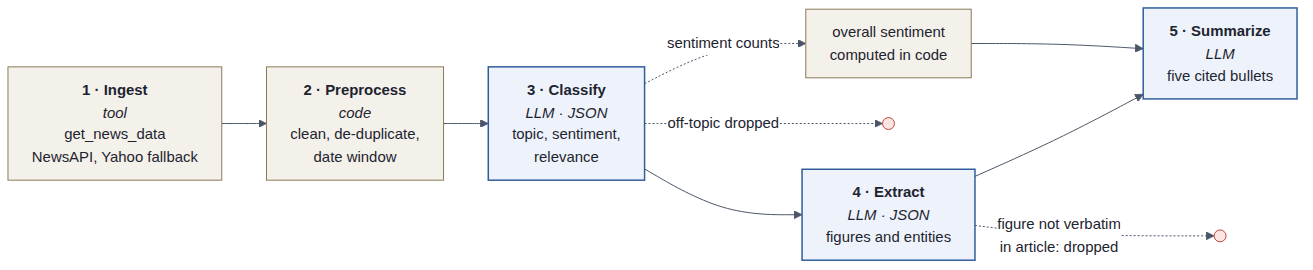

The cell prints the output of each stage.

In [26]:
news_analyst = news_analyst_agent(llm=llm)
news_response = news_analyst.run("Analyse NVDA")

for step in news_response.trace:
    stage = step.metadata.get("stage") or step.step_type
    if step.step_type == "tool_call":
        print(f"[Ingest] tool call: {step.content['tool']}({step.content['arguments']})")
    elif step.step_type in ("tool_result", "observation", "thought", "error"):
        print(f"[{stage}] {short(step.content, 160)}")

print("\n=== Final news digest (stage 5 output) ===")
show_md(news_response.content)

[Ingest] tool call: get_news_data({'ticker': 'NVDA', 'days': 30})
[tool_result] {"ticker": "NVDA", "from": "2026-09-17", "to": "2026-10-17", "articles": [], "error": "All news sources failed for 'NVDA': NewsAPI: NEWS_API_KEY is not set. ...
[preprocess] {"stage": "preprocess", "result": {"received": 0, "kept": 0, "dropped": {}}}

=== Final news digest (stage 5 output) ===


No news data available from tools for NVDA (All news sources failed for 'NVDA': NewsAPI: NEWS_API_KEY is not set. Add it to .env to enable live news search.; yfinance: yfinance returned no news for 'NVDA').

## 13. W2 - Routing: each request goes to the right place

Routing happens at two levels:
* **Planner route** (`route_planner` in `workflows/graph.py`): a research request goes to the
  orchestrator; a general question, greeting or off-topic request is answered directly (END).
* **Router** (`ResearchRouter`): decides *which* specialists a research request needs. A question
  only about earnings goes to the Earnings analyst; "Analyse NVDA" goes to all three.

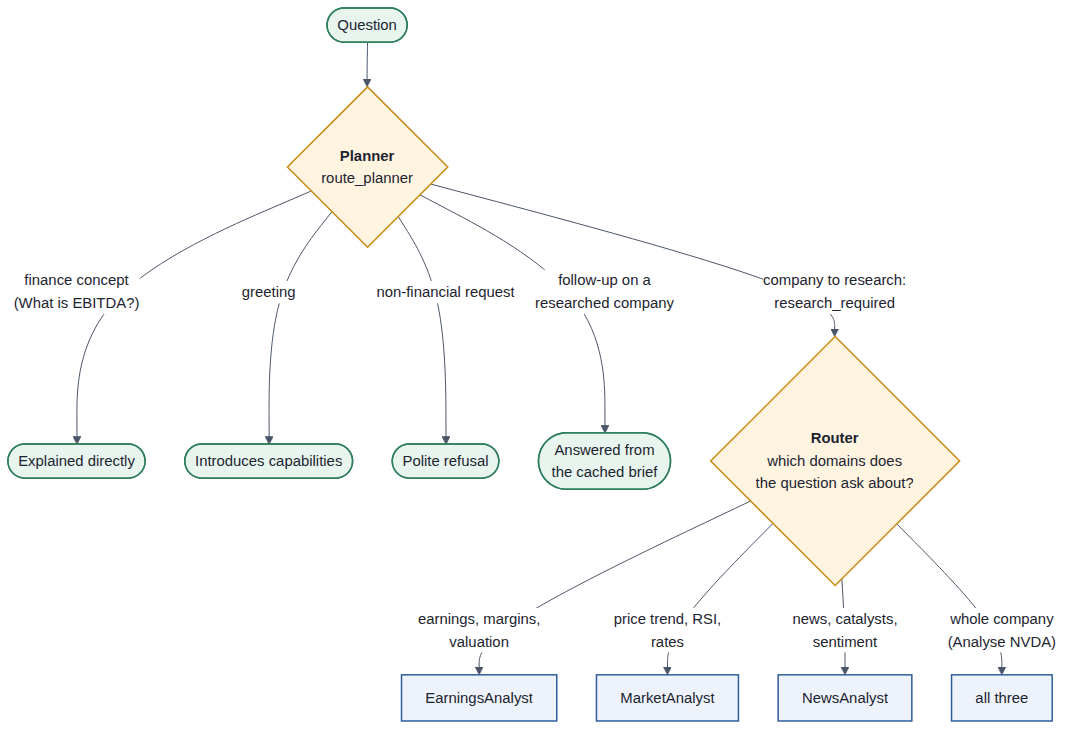

The table runs the planner on eight test inputs and, for research requests, records the specialists
the router delegates to (the specialists themselves are not run for this table).

In [27]:
from research_agent.agents import (
    earnings_analyst_agent,
    market_analyst_agent,
    news_analyst_agent,
    router_agent,
)
from research_agent.workflows.graph import route_planner

router = router_agent(
    llm=llm,
    subagents=[
        earnings_analyst_agent(llm=llm),
        market_analyst_agent(llm=llm),
        news_analyst_agent(llm=llm),
    ],
    verbose=False,
)


SPECIALIST_NAMES = {
    "earningsanalyst": "Earnings",
    "marketanalyst": "Market",
    "newsanalyst": "News",
}


def router_choice(question: str, max_turns: int = 4) -> list[str]:
    """Specialists the router delegates to, without running them.

    The router is a ReAct agent that may delegate one specialist per turn, so each
    delegation gets a placeholder result and the router is asked again until it stops.
    """
    messages = [
        {"role": "system", "content": router._format_system_prompt()},
        {"role": "user", "content": question},
    ]
    chosen: list[str] = []
    for _ in range(max_turns):
        _, calls, raw_message = llm.chat(messages, router.tools)
        if not calls:
            break
        messages.append(raw_message)
        for call in calls:
            # Only delegations count; any other tool name the model invents is ignored.
            name = SPECIALIST_NAMES.get(call["name"].replace("delegate_to_", ""))
            if name and call["name"].startswith("delegate_to_"):
                chosen.append(name)
            messages.append({"role": "tool", "content": "(routing demo: not run)"})
    return list(dict.fromkeys(chosen)) or ["(answered directly)"]


test_inputs = [
    "Analyse NVDA",
    "How are Apple's latest earnings and margins?",
    "What is the price trend and RSI for Tesla?",
    "Any recent news catalysts for Exxon Mobil?",
    "What is EBITDA?",
    "Hi, what can you do?",
    "What's the weather in Tokyo?",
    "Compare JPMorgan's fundamentals and news sentiment",
]

rows = []
for question in test_inputs:
    response = planner_agent(llm=llm, tools=GraphMemory().as_tools()).run(question)
    state = GraphState(question=question)
    state.agents["ResearchPlanner"] = response.content
    route = route_planner(state)
    data = response.data or {}
    rows.append(
        {
            "Input": question,
            "Planner route": "research (orchestrator)" if route != END else "answer directly",
            "Ticker": data.get("ticker", "-"),
            "Router: specialists": ", ".join(router_choice(question)) if route != END else "-",
        }
    )

routing_table = pd.DataFrame(rows)
routing_table

,Input,Planner route,Ticker,Router: specialists
0,Analyse NVDA,research (orchestrator),-,"Earnings, Market, News"
1,How are Apple's latest earnings and margins?,answer directly,-,-
2,What is the price trend and RSI for Tesla?,research (orchestrator),TSLA,Market
3,Any recent news catalysts for Exxon Mobil?,research (orchestrator),XOM,News
4,What is EBITDA?,answer directly,-,-
5,"Hi, what can you do?",answer directly,-,-
6,What's the weather in Tokyo?,answer directly,-,-
7,Compare JPMorgan's fundamentals and news sentiment,research (orchestrator),-,"Earnings, News"


## 14. W3 - Evaluator-optimizer: generate, evaluate, refine

The Draft writer generates, the Critic evaluates (section 9) and the **Refiner** improves the draft
using the Critic's feedback:
* It rewrites only the flagged sections, at most five issues per round, blockers first, and may call
  the data tools again to replace an unsupported figure.
* It returns a change log, and the revised draft goes back to the Critic.
* The loop stops on a PASS, after 3 refinements, or when a round improves the score by less than
  0.5. `release` then returns the best-scoring version, with reviewer notes if none passed.

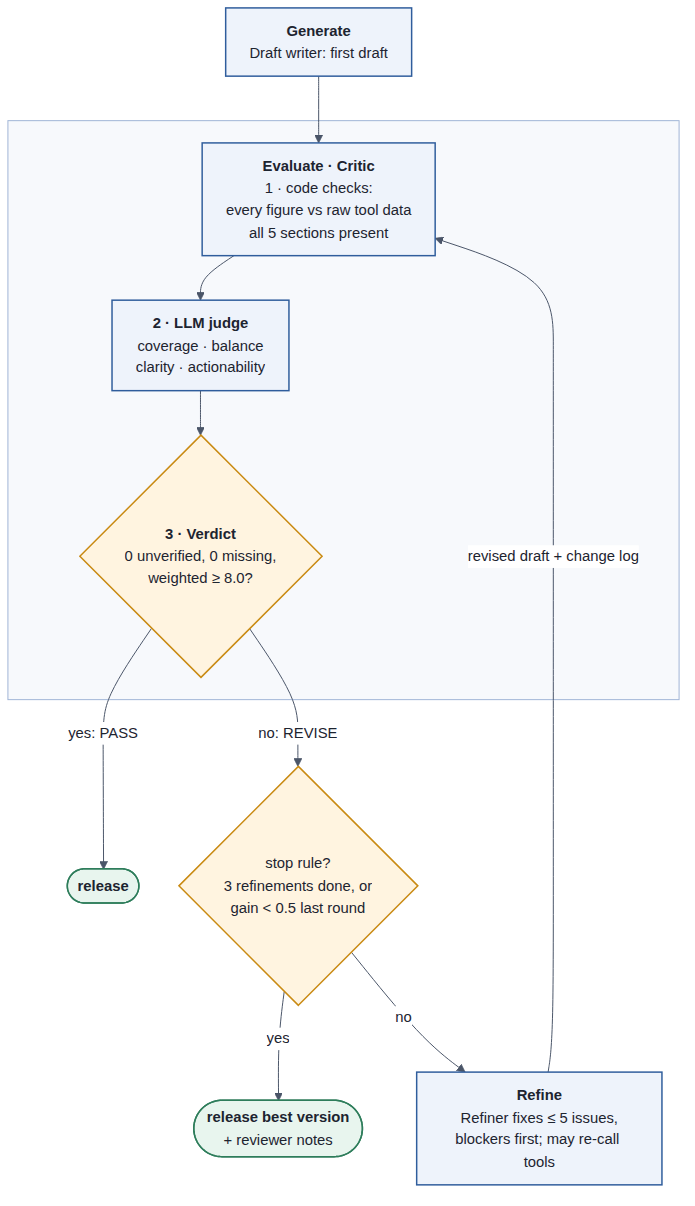

The cells below show what the Refiner changed between the first two versions, the score per round,
and a test that the evaluator catches a planted wrong number.

### 14.1 What the Refiner changed
Lines removed (`-`) and added (`+`) between the first draft and the first refinement.

In [28]:
# Draft v1 -> v2: what the Refiner changed (unified diff of the first two versions).
import difflib

if len(history) > 1:
    diff = difflib.unified_diff(
        history[0]["brief"].splitlines(),
        history[1]["brief"].splitlines(),
        "draft v1",
        "draft v2",
        lineterm="",
        n=0,
    )
    changed = [line for line in diff if line.startswith(("+", "-"))]
    print("\n".join(short(line, 150) for line in changed[:40]))
    print(f"\n({len(changed)} changed lines in total)")
else:
    print("The first draft passed review, so no refinement was needed.")

--- draft v1
+++ draft v2
+```markdown
-- Revenue (TTM): $27.96B (≈ 35% YoY growth)
-- Gross Margin: 64.1% (≈ 10% expansion from Q4 2022)
-- Operating Income: $7.35B (≈ 26% increase from Q4 2022)
-- Net Margin: 23.5% (≈ 5% expansion from Q4 2022)
-- Free Cash Flow: $4.83B (≈ 67% increase from Q4 2022)
-- Forward P/E: 23.45 (≈ 20% discount to historical baseline)
-- EV/EBITDA: 14.32 (≈ 10% discount to historical baseline)
-- Revenue Multiples: 5.27 (≈ 15% premium to historical baseline)
+- Revenue (TTM):
+- Gross Margin:
+- Operating Income:
+- Net Margin:
+- Free Cash Flow:
+- Forward P/E:
+- EV/EBITDA:
+- Revenue Multiples:
-- Current Price: $543.48
-- 50-Day SMA: $522.93 (≈ 4.2% above current price)
-- 200-Day SMA: $446.45 (≈ 21.6% above current price)
-- 14-Day RSI: 64.23 (≈ oversold, indicating potential upside)
-- Stock Beta: 1.65 (≈ 25% above market average)
-- Trading Range: $444.83 - $742.65
+- Current Price:
+- 50-Day SMA:
+- 200-Day SMA:
+- 14-Day RSI:
+- Stock Beta:
+- Tradi

### 14.2 Score per review round
The weighted Critic score of each version, with the number of unverified figures. The dashed line is the pass mark.

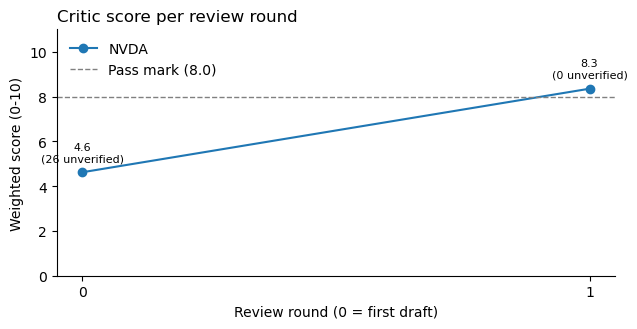

In [29]:
# Critic score per review round for this run (the evaluator-optimizer loop at work).
import matplotlib.pyplot as plt

main_stats = round_stats(main_state)
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(range(len(main_stats["scores"])), main_stats["scores"], marker="o", label="NVDA")
for i, (score, unverified) in enumerate(
    zip(main_stats["scores"], main_stats["unverified"], strict=True)
):
    ax.annotate(
        f"{score:.1f}\n({unverified} unverified)",
        (i, score),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center",
        fontsize=8,
    )
ax.axhline(8.0, color="grey", linestyle="--", linewidth=1, label="Pass mark (8.0)")
ax.set_xticks(range(len(main_stats["scores"])))
ax.set_ylim(0, 11)
ax.set_xlabel("Review round (0 = first draft)")
ax.set_ylabel("Weighted score (0-10)")
ax.set_title("Critic score per review round", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
fig.tight_layout()

### 14.3 Critic test: a planted wrong number is caught

Taking the released brief, we change one verified dollar figure and review it again. The code
check must list the planted figure as unverified and the verdict must be REVISE (design doc §5.2).

In [30]:
from research_agent.workflows.review_loop import (
    Critic,
    _parse_figures,
    check_grounding,
    evidence_numbers,
)

released = main_state.output.split("\n---\n### Reviewer notes")[0]
evidence = evidence_numbers(main_state.tools)

# Plant a wrong number: take a figure the data verifies, preferring large dollar amounts,
# then any dollar amount, then any other figure, and inflate it by 37%.
verified = [
    f
    for line in released.splitlines()
    for f in _parse_figures(line)
    if evidence.matches(f) is not None and re.search(r"\d", f.text)
]
target = next(
    (f for f in verified if f.kind == "money" and f.value >= 1e6),
    next((f for f in verified if f.kind == "money"), verified[0] if verified else None),
)
if target is None:
    # The released brief quotes nothing the data verifies (a weak draft). Test the Critic on a
    # one-line brief built from a real tool figure instead, so the check does not depend on it.
    money = [v for v, kind in evidence.figures if kind in ("money", "plain") and abs(v) >= 1e6]
    if not money:
        raise RuntimeError(
            f"The tool data holds no dollar figure ({len(evidence.figures)} numbers in total), "
            "so section 6 did not fetch usable data. Re-run section 6."
        )
    released = f"Reported revenue was ${abs(money[0]) / 1e9:.2f}B in the latest quarter."
    target = next(f for f in _parse_figures(released) if evidence.matches(f) is not None)
    print(f"No verified figure in the released brief; testing on: {released}")
number = re.search(r"\d[\d,]*(?:\.\d+)?", target.text).group(0)
wrong = f"{float(number.replace(',', '')) * 1.37:.2f}"
assert number in released
planted_brief = released.replace(number, wrong, 1)

before = check_grounding(released, evidence).unverified
report = Critic(llm).review(planted_brief, main_state.tools, main_question, round_no=0)
newly_flagged = [f for f in report.unverified if f not in before]
print(f"Planted change       : {number} -> {wrong}  (in '{target.text}')")
print(f"Newly unverified     : {newly_flagged}")
print(f"Grounding score      : {report.scores['grounding']}/10")
print(f"Verdict              : {'PASS' if report.passed else 'REVISE'}")
assert any(wrong in f for f in newly_flagged), "the planted figure must be flagged"
assert not report.passed, "the Critic must block a brief with a planted wrong number"

RuntimeError: The tool data holds no dollar figure (0 numbers in total), so section 6 did not fetch usable data. Re-run section 6.

# Part IV. Evaluation and iteration

## 15. Evaluation

End-to-end evaluation across several tickers (design doc §5.1): Critic score per refinement round,
pass rate, unverified figures before and after refinement, and run time.

### 15.1 Five-Ticker Evaluation

The function below researches five companies from different sectors, each in its own new conversation, and records the Critic score of every review round. Two charts follow: the score per refinement round for each ticker, and the final (released) score per ticker.

| Ticker | Company | Sector |
| :-- | :-- | :-- |
| AAPL | Apple | Consumer technology |
| NVDA | NVIDIA | Semiconductors |
| JPM | JPMorgan Chase | Financials |
| XOM | Exxon Mobil | Energy |
| TSLA | Tesla | Automotive / EV |

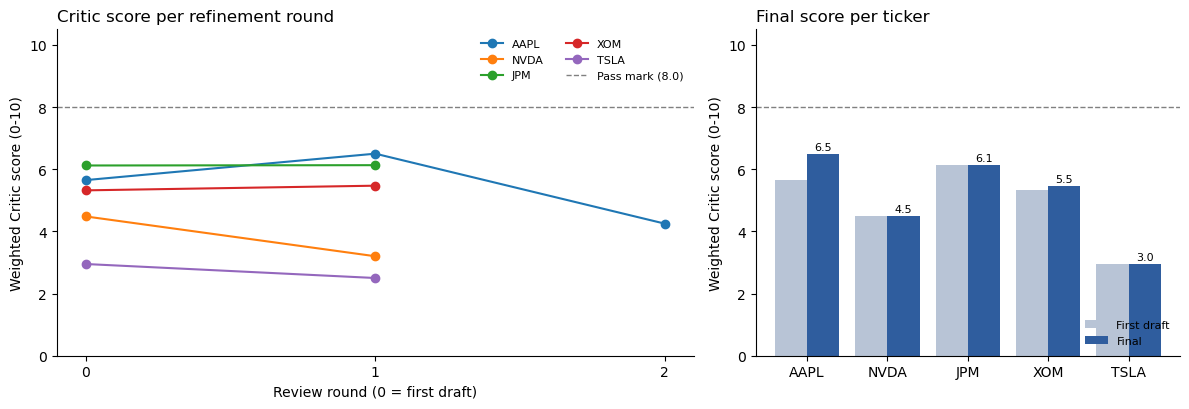

,Ticker,Sector,Rounds,First-draft score,Final score,Gain,Unverified (first -> last),Passed,Latency (s),LLM calls,Input tokens,Output tokens,Est. cost ($)
0,AAPL,Consumer technology,3,5.65,6.50,0.85,19 -> 19,False,272.3,8,13213,4297,0.0046
1,NVDA,Semiconductors,2,4.48,4.48,0.00,17 -> 18,False,157.4,6,10676,2527,0.0031
2,JPM,Financials,2,6.12,6.13,0.01,24 -> 22,False,226.2,7,13140,3545,0.0041
3,XOM,Energy,2,5.32,5.47,0.15,25 -> 25,False,209.2,7,12570,3030,0.0037
4,TSLA,Automotive / EV,2,2.95,2.95,0.00,21 -> 2,False,165.8,7,12043,2706,0.0034


In [31]:
import contextlib
import tempfile
import threading

import matplotlib.pyplot as plt

from research_agent.memory import LongTermMemory

EVAL_TICKERS = {
    "AAPL": ("Apple", "Consumer technology"),
    "NVDA": ("NVIDIA", "Semiconductors"),
    "JPM": ("JPMorgan Chase", "Financials"),
    "XOM": ("Exxon Mobil", "Energy"),
    "TSLA": ("Tesla", "Automotive / EV"),
}
PASS_MARK = 8.0
# ---------------------------------------------------------------------------
# Latency and token usage per run
# ---------------------------------------------------------------------------
# The LLM wrappers return only the message, so token counts are read from the raw SDK
# responses by wrapping each client's call once. Ollama reports prompt_eval_count and
# eval_count; OpenAI-compatible clients (the Groq fallback) report usage.prompt_tokens and
# usage.completion_tokens.
# ASSUMED prices in USD per 1M tokens: replace them with your provider's rates. Ollama Cloud
# is flat-rate, so the cost column is an estimate at these rates, not a bill.
PRICE_PER_1M_TOKENS = {"input": 0.15, "output": 0.60}

_usage_lock = threading.Lock()
_usage = {"calls": 0, "input": 0, "output": 0}


def _record_usage(prompt_tokens, completion_tokens):
    with _usage_lock:
        _usage["calls"] += 1
        _usage["input"] += int(prompt_tokens or 0)
        _usage["output"] += int(completion_tokens or 0)


def _wrap_call(owner, attribute, reader):
    """Wrap ``owner.attribute`` once so every response is counted."""
    original = getattr(owner, attribute)
    if getattr(original, "_usage_wrapped", False):
        return

    def counted(*args, **kwargs):
        response = original(*args, **kwargs)
        with contextlib.suppress(Exception):
            _record_usage(*reader(response))
        return response

    counted._usage_wrapped = True
    setattr(owner, attribute, counted)


def _install_usage_counter():
    from research_agent.interfaces import llm as llm_module

    for cls, attach in (
        (llm_module.OllamaLLM, lambda client: _wrap_call(
            client, "chat",
            lambda r: (getattr(r, "prompt_eval_count", 0), getattr(r, "eval_count", 0)))),
        (llm_module.OpenAILLM, lambda client: _wrap_call(
            client.chat.completions, "create",
            lambda r: (r.usage.prompt_tokens, r.usage.completion_tokens))),
    ):
        original_chat = cls.chat
        if getattr(original_chat, "_usage_wrapped", False):
            continue

        def chat(self, *args, _orig=original_chat, _attach=attach, **kwargs):
            with contextlib.suppress(Exception):
                _attach(self.client)  # no-op after the first call on this client
            return _orig(self, *args, **kwargs)

        chat._usage_wrapped = True
        cls.chat = chat


_install_usage_counter()


class TrackUsage:
    """Context manager: wall-clock latency and LLM tokens used inside the ``with`` block.

    After the block, ``.seconds``, ``.calls``, ``.input_tokens``, ``.output_tokens`` and
    ``.cost`` (USD at PRICE_PER_1M_TOKENS) are set. Do not run two tracked blocks at once.
    """

    def __enter__(self):
        with _usage_lock:
            self._start = dict(_usage)
        self._t0 = time.time()
        return self

    def __exit__(self, *exc):
        self.seconds = time.time() - self._t0
        with _usage_lock:
            end = dict(_usage)
        self.calls = end["calls"] - self._start["calls"]
        self.input_tokens = end["input"] - self._start["input"]
        self.output_tokens = end["output"] - self._start["output"]
        self.cost = (
            self.input_tokens * PRICE_PER_1M_TOKENS["input"]
            + self.output_tokens * PRICE_PER_1M_TOKENS["output"]
        ) / 1e6
        return False


EVAL_STATES = {}  # symbol -> final GraphState, filled by evaluate_tickers (used in 15.1)


def research_question(symbol, company):
    return (
        f"Provide an institutional equity research briefing on {symbol} ({company}) "
        "covering fundamentals, valuation, technical momentum, and news catalysts."
    )


def ask_until_researched(symbol, company, memory_factory, attempts=3, tag="eval"):
    """Ask for a brief, retrying when the Planner answers in prose instead of dispatching.

    The Planner is an LLM. Now and then it replies with a plain-text plan instead of the JSON
    dispatch, the graph then ends at the Planner, and no Critic review exists. A retry in a new
    conversation almost always dispatches. Latency and tokens of every attempt are counted.
    Returns (final state, usage of all attempts).
    """
    with TrackUsage() as usage:
        for attempt in range(1, attempts + 1):
            session = ResearchSession(
                thread_id=f"{tag}-{symbol.lower()}-{attempt}-{int(time.time())}",
                long_term=memory_factory(),
            )
            session.ask(research_question(symbol, company), show=False)
            state = session.last_state
            if getattr(state, "review", None) and state.review.get("history"):
                return state, usage
            print(
                f"{symbol}: attempt {attempt}/{attempts} was not researched "
                "(Planner did not dispatch)"
            )
    return state, usage


def evaluate_tickers(tickers=EVAL_TICKERS, reuse_state=None, use_memory=False):
    """Research each ticker end to end, chart score per round and final score per ticker.

    tickers     : {symbol: (company name, sector)}
    reuse_state : optional {symbol: GraphState} of runs already done (e.g. {"NVDA": main_state})
    use_memory  : False keeps every run independent of long-term lessons (a fair comparison)
    Returns a DataFrame with one row per ticker.
    """
    reuse_state = reuse_state or {}
    rows, histories = [], {}
    for symbol, (company, sector) in tickers.items():
        if symbol in reuse_state:
            state, elapsed, usage = reuse_state[symbol], float("nan"), None
        else:
            # long_term=None would fall back to the shared default store, so a throwaway
            # directory keeps every run free of earlier lessons.
            try:
                state, usage = ask_until_researched(
                    symbol,
                    company,
                    lambda: long_term if use_memory else LongTermMemory(tempfile.mkdtemp()),
                )
            except Exception as exc:  # one failing ticker must not stop the evaluation
                print(f"{symbol}: run failed ({type(exc).__name__}: {exc})")
                continue
            elapsed = usage.seconds
        if not getattr(state, "review", None) or not state.review.get("history"):
            print(f"{symbol}: no review history after all attempts (request was not researched)")
            continue
        EVAL_STATES[symbol] = state
        stats = round_stats(state)
        histories[symbol] = stats
        rows.append(
            {
                "Ticker": symbol,
                "Sector": sector,
                "Rounds": len(stats["scores"]),
                "First-draft score": stats["first_draft"],
                "Final score": stats["released"],
                "Gain": round(stats["released"] - stats["first_draft"], 2),
                "Unverified (first -> last)": (
                    f"{stats['unverified'][0]} -> {stats['unverified'][-1]}"
                ),
                "Passed": stats["passed"],
                "Latency (s)": round(elapsed, 1) if elapsed == elapsed else None,
                "LLM calls": usage.calls if usage else None,
                "Input tokens": usage.input_tokens if usage else None,
                "Output tokens": usage.output_tokens if usage else None,
                "Est. cost ($)": round(usage.cost, 4) if usage else None,
            }
        )
    table = pd.DataFrame(rows)
    if table.empty:
        print("No ticker produced a review history.")
        return table

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [3, 2]})

    # Chart 1: Critic score per refinement round, one line per ticker.
    for symbol, stats in histories.items():
        ax1.plot(range(len(stats["scores"])), stats["scores"], marker="o", label=symbol)
    ax1.axhline(
        PASS_MARK, color="grey", linestyle="--", linewidth=1, label=f"Pass mark ({PASS_MARK})"
    )
    max_rounds = max(len(s["scores"]) for s in histories.values())
    ax1.set_xticks(range(max_rounds))
    ax1.set_ylim(0, 10.5)
    ax1.set_xlabel("Review round (0 = first draft)")
    ax1.set_ylabel("Weighted Critic score (0-10)")
    ax1.set_title("Critic score per refinement round", loc="left")
    ax1.legend(frameon=False, fontsize=8, ncol=2)

    # Chart 2: final (released) score per ticker, with the first draft for reference.
    x = range(len(table))
    ax2.bar(
        [i - 0.2 for i in x], table["First-draft score"],
        width=0.4, color="#b8c4d6", label="First draft",
    )
    bars = ax2.bar(
        [i + 0.2 for i in x], table["Final score"], width=0.4, color="#2f5d9e", label="Final"
    )
    for bar, score in zip(bars, table["Final score"], strict=True):
        ax2.annotate(f"{score:.1f}", (bar.get_x() + bar.get_width() / 2, score),
                     textcoords="offset points", xytext=(0, 3), ha="center", fontsize=8)
    ax2.axhline(PASS_MARK, color="grey", linestyle="--", linewidth=1)
    ax2.set_xticks(list(x))
    ax2.set_xticklabels(table["Ticker"])
    ax2.set_ylim(0, 10.5)
    ax2.set_ylabel("Weighted Critic score (0-10)")
    ax2.set_title("Final score per ticker", loc="left")
    ax2.legend(frameon=False, fontsize=8, loc="lower right")

    for ax in (ax1, ax2):
        ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    plt.show()
    display(table)
    return table


# All five tickers are researched in fresh conversations.
eval_table = evaluate_tickers()

### 15.2 Accuracy check against yfinance

Each released brief is checked against fresh yfinance data using 10 evenly distributed figures covering company ratios, price history, and financial statements. Figures are **confirmed** if they match within rounding tolerance or 2%. Accuracy is the percentage of confirmed figures.
Limitations: Agent-calculated figures and data from news or filings may lack matching yfinance fields, so “not found” does not mean incorrect. Matched fields are shown for manual verification.

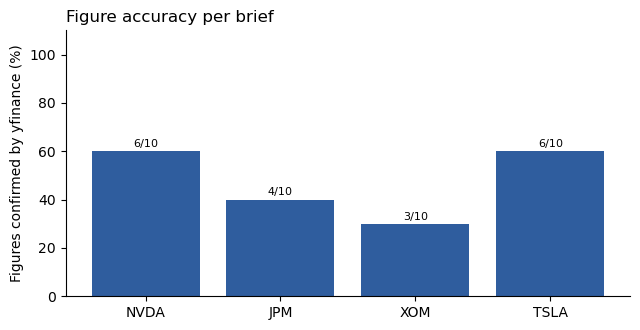

Overall: 19 of 40 figures confirmed (48%)


,Ticker,Checked,Confirmed,Accuracy
0,NVDA,10,6,60.0
1,JPM,10,4,40.0
2,XOM,10,3,30.0
3,TSLA,10,6,60.0


,Ticker,Figure,Context,yfinance field,Confirmed
0,NVDA,$11.7B,Revenue Growth**: $11.7B (≈25% YoY growth),quarterly_balance_sheet.Non Current Deferred Assets[2026-04-30],True
1,NVDA,25%,Revenue Growth**: $11.7B (≈25% YoY growth),info.lastDividendValue,True
2,NVDA,$2.3B,Operating Income**: $2.3B (≈$1.1B operating income margin),income_stmt.Interest Income[2026-01-31],True
3,NVDA,$2.1B,Net Income**: $2.1B (≈$10.50 EPS),balance_sheet.Non Current Prepaid Assets[2025-01-31],True
4,NVDA,25.6,Forward P/E**: 25.6 (≈10% premium to industry median),info.enterpriseToEbitda,True
5,NVDA,10%,Forward P/E**: 25.6 (≈10% premium to industry median),info.boardRisk,True
6,NVDA,"$1,215.10","Stock Price**: $1,215.10 (≈15% YoY appreciation)",-,False
7,NVDA,70.2,Relative Strength Index (RSI)**: 70.2 (≈neutral zone),-,False
8,NVDA,"$1,050.50","200-Day SMA**: $1,050.50 (≈long-term support level)",-,False
9,NVDA,"$1,530.00","52-Week Range**: $1,025.00 - $1,530.00",-,False


In [32]:
import numpy as np
import yfinance as yf

from research_agent.workflows.review_loop import _parse_figures


def yfinance_reference(symbol):
    """Numbers yfinance reports for ``symbol``, as {field name: value}."""
    tk = yf.Ticker(symbol)
    ref = {}
    with contextlib.suppress(Exception):
        for key, value in (tk.info or {}).items():
            if isinstance(value, (int, float)) and not isinstance(value, bool):
                ref[f"info.{key}"] = float(value)
    with contextlib.suppress(Exception):
        hist = tk.history(period="1y")
        close, volume = hist["Close"].dropna(), hist["Volume"].dropna()
        ref.update(
            {
                "price.close": close.iloc[-1],
                "price.sma50": close.tail(50).mean(),
                "price.sma200": close.tail(200).mean(),
                "price.high_52w": close.max(),
                "price.low_52w": close.min(),
                "price.volume": volume.iloc[-1],
                "price.avg_volume_3m": volume.tail(63).mean(),
            }
        )
        delta = close.diff()
        gain, loss = delta.clip(lower=0).tail(14).mean(), -delta.clip(upper=0).tail(14).mean()
        ref["price.rsi14"] = 100 - 100 / (1 + gain / loss) if loss else 100.0
    for name in (
        "quarterly_income_stmt",
        "income_stmt",
        "quarterly_cashflow",
        "cashflow",
        "quarterly_balance_sheet",
        "balance_sheet",
    ):
        with contextlib.suppress(Exception):
            frame = getattr(tk, name)
            for column in list(frame.columns)[:2]:  # latest two periods
                for row, value in frame[column].dropna().items():
                    ref[f"{name}.{row}[{str(column)[:10]}]"] = float(value)
    return {k: float(v) for k, v in ref.items() if v == v}


def match_reference(figure, ref, rel_tol=0.02):
    """Name of the yfinance field that ``figure`` agrees with, or None."""
    target = abs(figure.value)
    allowed = max(figure.tolerance, rel_tol * target)
    # A percentage may be stored as a fraction (0.62 -> 62%).
    scales = (1.0, 100.0) if figure.kind == "percent" else (1.0,)
    best = None
    for name, value in ref.items():
        for scale in scales:
            gap = abs(target - abs(value) * scale)
            if gap <= allowed and (best is None or gap < best[0]):
                best = (gap, name)
    return best[1] if best else None


def verify_figures(brief, symbol, n=10, ref=None):
    """Check ``n`` cited figures of ``brief`` against yfinance; returns one row per figure."""
    brief = brief.split("\n---\n### Reviewer notes")[0]
    ref = ref or yfinance_reference(symbol)
    unique, seen = [], set()
    for line in brief.splitlines():
        if line.lstrip().startswith("#"):
            continue
        for figure in _parse_figures(line):
            key = (figure.kind, round(figure.value, 6))
            if key not in seen:  # one entry per distinct value
                seen.add(key)
                unique.append((figure, line))
    if not unique:
        return pd.DataFrame()
    picks = [unique[i] for i in np.linspace(0, len(unique) - 1, min(n, len(unique))).astype(int)]
    rows = []
    for figure, line in picks:
        field = match_reference(figure, ref)
        rows.append(
            {
                "Ticker": symbol,
                "Figure": figure.text,
                "Context": short(line.strip("|-* "), 70),
                "yfinance field": field or "-",
                "Confirmed": field is not None,
            }
        )
    return pd.DataFrame(rows)


def accuracy_report(states=None, n=10):
    """Run the yfinance check on every brief in ``states`` and chart accuracy per ticker."""
    states = states or EVAL_STATES
    if not states:
        print("No briefs yet: run the evaluation cell above first.")
        return pd.DataFrame()
    details = pd.concat(
        [verify_figures(state.output, symbol, n) for symbol, state in states.items()],
        ignore_index=True,
    )
    summary = (
        details.groupby("Ticker", sort=False)["Confirmed"]
        .agg(Checked="size", Confirmed="sum")
        .assign(Accuracy=lambda d: (100 * d["Confirmed"] / d["Checked"]).round(0))
        .reset_index()
    )
    fig, ax = plt.subplots(figsize=(6.5, 3.4))
    bars = ax.bar(summary["Ticker"], summary["Accuracy"], color="#2f5d9e")
    for bar, row in zip(bars, summary.itertuples(), strict=True):
        ax.annotate(
            f"{row.Confirmed}/{row.Checked}",
            (bar.get_x() + bar.get_width() / 2, row.Accuracy),
            textcoords="offset points",
            xytext=(0, 3),
            ha="center",
            fontsize=8,
        )
    ax.set_ylim(0, 110)
    ax.set_ylabel("Figures confirmed by yfinance (%)")
    ax.set_title("Figure accuracy per brief", loc="left")
    ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    plt.show()
    total = int(details["Confirmed"].sum())
    pct = 100 * total / len(details)
    print(f"Overall: {total} of {len(details)} figures confirmed ({pct:.0f}%)")
    display(summary)
    display(details)
    return details


accuracy_table = accuracy_report()

### 15.3 Long-term memory (F4): one ticker researched twice

The same ticker is researched twice in separate conversations: Run 1 starts with empty memory; Run 2 uses lessons from researching seed tickers and Run 1’s dated note. First drafts are compared before Critic feedback. Temporary memory preserves existing long-term memory. Due to LLM variability, the comparison illustrates the mechanism, not guaranteed improvement.

In [33]:
def memory_effect(ticker="NVDA", seed_tickers=("AAPL",)):
    """Research ``ticker`` twice (empty memory, then with memory) and compare first drafts."""
    memory = LongTermMemory(tempfile.mkdtemp())

    def run(symbol, label):
        company = EVAL_TICKERS.get(symbol, (symbol,))[0]
        state, _ = ask_until_researched(symbol, company, lambda: memory, tag=f"mem-{label}")
        if not getattr(state, "review", None) or not state.review.get("history"):
            raise RuntimeError(f"{symbol} was not researched after retries; run the cell again")
        return state

    first = round_stats(run(ticker, "run1"))
    for symbol in seed_tickers:
        run(symbol, "seed")
    context = memory.context_for(ticker)
    lessons, notes = len(context.get("critic_lessons", [])), len(context.get("ticker_notes", []))
    second = round_stats(run(ticker, "run2"))

    table = pd.DataFrame(
        [
            {
                "Run": f"{ticker} run 1 (empty memory)",
                "Active lessons": 0,
                "Earlier notes": 0,
                "First-draft score": first["first_draft"],
                "First-draft unverified": first["first_unverified"],
                "Released score": first["released"],
            },
            {
                "Run": f"{ticker} run 2 (with memory)",
                "Active lessons": lessons,
                "Earlier notes": notes,
                "First-draft score": second["first_draft"],
                "First-draft unverified": second["first_unverified"],
                "Released score": second["released"],
            },
        ]
    )
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
    labels = ["Run 1\n(empty memory)", "Run 2\n(with memory)"]
    for ax, column, title in [
        (axes[0], "First-draft score", "First-draft Critic score"),
        (axes[1], "First-draft unverified", "First-draft unverified figures"),
    ]:
        bars = ax.bar(labels, table[column], color=["#b8c4d6", "#2f5d9e"])
        for bar, value in zip(bars, table[column], strict=True):
            ax.annotate(
                f"{value:g}",
                (bar.get_x() + bar.get_width() / 2, value),
                textcoords="offset points",
                xytext=(0, 3),
                ha="center",
                fontsize=9,
            )
        ax.set_title(title, loc="left")
        ax.spines[["top", "right"]].set_visible(False)
    axes[0].axhline(PASS_MARK, color="grey", linestyle="--", linewidth=1)
    axes[0].set_ylim(0, 10.5)
    fig.tight_layout()
    plt.show()
    display(table)
    delta = second["first_draft"] - first["first_draft"]
    print(f"First-draft score change with memory: {delta:+.2f}")
    return table


memory_table = memory_effect("NVDA")

NVDA: attempt 1/3 was not researched (Planner did not dispatch)
NVDA: attempt 2/3 was not researched (Planner did not dispatch)
NVDA: attempt 3/3 was not researched (Planner did not dispatch)


RuntimeError: NVDA was not researched after retries; run the cell again

### 15.4 Latency and token cost per run

Each run tracks execution time and LLM input/output tokens. Costs use placeholder rates in `PRICE_PER_1M_TOKENS`; replace them with actual provider rates. Groq fallback usage is included, but unreported token usage counts as zero, so verify against the LLM call count.

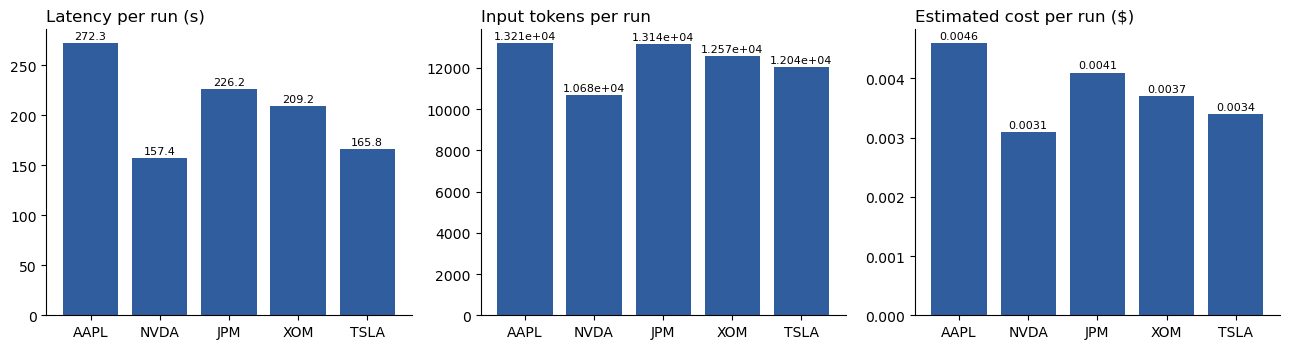

Total: 1031 s, 35 LLM calls, 61,642 input + 16,105 output tokens, about $0.019 at the assumed prices


,Ticker,Latency (s),LLM calls,Input tokens,Output tokens,Est. cost ($)
0,AAPL,272.3,8,13213,4297,0.0046
1,NVDA,157.4,6,10676,2527,0.0031
2,JPM,226.2,7,13140,3545,0.0041
3,XOM,209.2,7,12570,3030,0.0037
4,TSLA,165.8,7,12043,2706,0.0034


In [34]:
def plot_latency_and_cost(table):
    """Bar charts of latency (s) and estimated cost ($) per ticker, plus tokens in the table."""
    data = table.dropna(subset=["Latency (s)"])
    if data.empty:
        print("No timed runs in the table.")
        return
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
    for ax, column, title in [
        (axes[0], "Latency (s)", "Latency per run (s)"),
        (axes[1], "Input tokens", "Input tokens per run"),
        (axes[2], "Est. cost ($)", "Estimated cost per run ($)"),
    ]:
        bars = ax.bar(data["Ticker"], data[column], color="#2f5d9e")
        for bar, value in zip(bars, data[column], strict=True):
            ax.annotate(f"{value:,.4g}", (bar.get_x() + bar.get_width() / 2, value),
                        textcoords="offset points", xytext=(0, 3), ha="center", fontsize=8)
        ax.set_title(title, loc="left")
        ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    plt.show()
    columns = [
        "Ticker", "Latency (s)", "LLM calls",
        "Input tokens", "Output tokens", "Est. cost ($)",
    ]
    totals = data[columns[1:]].sum()
    print(
        f"Total: {totals['Latency (s)']:.0f} s, {int(totals['LLM calls'])} LLM calls, "
        f"{int(totals['Input tokens']):,} input + {int(totals['Output tokens']):,} output tokens, "
        f"about ${totals['Est. cost ($)']:.3f} at the assumed prices"
    )
    display(data[columns])


plot_latency_and_cost(eval_table)

## 16. Iteration and code quality

The system improves its output at two time scales, both shown with real runs above:

| Scale | Mechanism | Evidence in this notebook |
| :-- | :-- | :-- |
| Within one run | Critic and Refiner loop (W3): each round fixes the issues the Critic found | section 9 table and section 14 chart |
| Across runs | Long-term memory (F4): recurring first-draft weaknesses become lessons for the next draft | section 10 comparison |

The code was also developed iteratively, with each fix covered by a test. The repository follows
PEP 8 / PEP 257 (checked with `ruff`), uses type hints (`mypy`), and has an offline `pytest` suite
with scripted LLMs and stubbed data tools (above 90% line coverage). The cell below runs the tests
for the components demonstrated in this notebook.

In [ ]:
test_files = [
    "tests/test_review_loop.py",
    "tests/test_long_term_memory.py",
    "tests/test_news_chain.py",
    "tests/test_router.py",
    "tests/test_session.py",
]
try:
    import pytest  # noqa: F401
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pytest"], check=True)

result = subprocess.run(
    [
        sys.executable,
        "-m",
        "pytest",
        "-q",
        "--color=no",
        "-o",
        "addopts=",
        "-p",
        "no:cacheprovider",
        "--basetemp=.pytest_temp",
        *test_files,
    ],
    capture_output=True,
    text=True,
    check=False,  # failures are reported in the printed summary
)
print(result.stdout.strip().splitlines()[-1])


130 passed in 7.05s


## 17. Summary

| Requirement | How it is implemented | Demonstrated in |
| :-- | :-- | :-- |
| F1 Planning | Planner verifies the ticker with `lookup_ticker` and returns a JSON dispatch with an ordered research plan | Section 7 |
| F2 Dynamic tool use | Specialists choose tools and arguments at run time (yfinance, SEC EDGAR, FRED, NewsAPI, Alpha Vantage fallback) | Sections 3, 6, 8 |
| F3 Self-reflection | Critic: code grounding check against raw tool data + LLM judge on four dimensions | Section 9 |
| F4 Learning across runs | Long-term memory: ticker notes and Critic lessons that feed later runs | Section 10 |
| W1 Prompt chaining | News analyst: ingest, preprocess, classify, extract, summarize | Section 12 |
| W2 Routing | Planner routes research vs direct answers; router picks the specialists | Section 13 |
| W3 Evaluator-optimizer | Critic ⇄ Refiner loop with stopping rules and best-version release | Sections 9, 14 |

**Limitations.** The LLM judge's scores vary by about ±0.5 between runs, which can stop the loop
early on a plateau; free-tier API limits apply (results are cached); the system covers US-listed
equities. This is a research tool, not financial advice.

**Repository:** [https://github.com/diaeshantony-usd/investment-research-agent](https://github.com/diaeshantony-usd/investment-research-agent)

**Team:** Sai Krishna Akula (Planner, Router, Earnings analyst, orchestrator, CLI) · Ashok Kumar Bhairwal
(data tools and caching, Market analyst, Gradio UI, tests, evaluation) · Diaesh Antony (News prompt chain, Draft
writer, Critic, Refiner, session and long-term memory).

### AI-assistance disclosure
In line with the course policy on AI tools, the team discloses that an AI coding assistant (Claude)
was used to help draft, review and test parts of the code and of this notebook. All AI-assisted code
was reviewed, run and tested by the team, and each component is explained in this notebook.